# Caso 07: Inspecciones sanitarias de Chicago

## Integrantes:
- Graciela Gómez
- Benjamín Gutiérrez
- Juan Pablo Mondaca
- Benjamín Vargas

# 0. Librerias

In [ ]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

from time import perf_counter
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, brier_score_loss, confusion_matrix,
    ConfusionMatrixDisplay, f1_score, log_loss,
    precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from IPython.display import display
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    log_loss,
    roc_auc_score,
    confusion_matrix,
    recall_score,
    precision_score
)

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)


# 1. Carga base de datos

Todos los comentarios respecto a la decisión del filtrado se encuentran en la documentación.

In [2]:
datos = pd.read_csv("datos.csv", dtype=str)

print(datos.shape)
datos.head()

n_originales = len(datos)


(104468, 17)


# 2. Unificación y limpieza de variables

Todos los supuestos y consideraciones asumidas se encuentran en la documentación.

In [ ]:
# Bloque para definición de funciones:
def limpiar_texto(x):
    return (
        x.astype("string").str.upper().str.replace(r"\s+", " ", regex=True)
        .str.strip()
        .replace("", pd.NA))

# Convierte una columna a texto, pasa sus valores a mayúsculas,
# elimina espacios sobrantes y reemplaza los textos vacíos por NA.

def homologar_ciudad(x):
    ciudad = limpiar_texto(x)
    variantes_chicago = ["312CHICAGO","CCHICAGO","CH","CHICAGO",
        "CHICAGO.","CHICAGOBEDFORD PARK","CHICAGOC","CHICAGOCHICAGO","CHICAGOO"]

    return ciudad.mask(
        ciudad.isin(variantes_chicago),
        "CHICAGO")

# Limpia el texto y unifica las variantes de Chicago
# que definimos en nuestras reglas.

def obtener_riesgo_del_dia(x):
    valores = x.dropna().unique()
    if len(valores) == 1:
        return valores[0]
    return pd.NA

def agrupar_tipo(valor):
    if pd.isna(valor) or not str(valor).strip():
        return "Desconocido"
    s = re.sub(r"\s+", " ", str(valor).upper().strip())
    for grupo, patron in REGLAS:
        if re.search(patron, s):
            return grupo
    return "Otro"

def resumir_riesgo_del_dia(riesgos):
    codigos = riesgos.map(codigos_riesgo)

    # si hay riesgos conocidos, conservar el más alto
    riesgos_conocidos = codigos[codigos.isin([1, 2, 3])]

    if not riesgos_conocidos.empty:
        return int(riesgos_conocidos.min())

    # conservar All si no hay un riesgo conocido ese día.
    if codigos.eq(4).any():
        return 4

    # Todos los registros del día carecen de riesgo.
    return 0

def preparar_X(base):

    X = base[predictores].copy()

    # Conservar los faltantes numéricos.
    X[numericas] = X[numericas].astype("float64")

    # Tratar los códigos de riesgo y los booleanos como categorías.
    # Este reemplazo es fijo: no estima nada usando validación.
    for columna in categoricas:
        X[columna] = (
            X[columna]
            .astype("string")
            .fillna("SIN INFORMACION")
            .astype(object)
        )

    return X

def crear_logistica():

    preparacion_numericas = Pipeline([
        (
            "imputacion",
            SimpleImputer(
                strategy="median",
                add_indicator=True,
                keep_empty_features=True
            )
        ),
        (
            "escala",
            StandardScaler()
        )
    ])

    preparacion_categoricas = OneHotEncoder(
        drop="first",
        handle_unknown="ignore",
        sparse_output=False
    )

    preprocesamiento = ColumnTransformer([
        (
            "numericas",
            preparacion_numericas,
            numericas
        ),
        (
            "categoricas",
            preparacion_categoricas,
            categoricas
        )
    ])

    modelo = Pipeline([
        (
            "preprocesamiento",
            preprocesamiento
        ),
        (
            "logistica",
            LogisticRegression(
                C=np.inf,
                solver="lbfgs",
                max_iter=5000,
                class_weight=None
            )
        )
    ])

    return modelo

def crear_modelo_m2(nombre):
    parametros = parametros_m2[nombre]
    if nombre.startswith("arbol_podado_"):
        preparacion = clone(preparacion_arbol_m2)
        clasificador = DecisionTreeClassifier(random_state=3407, **parametros)
    else:
        preparacion = clone(preparacion_svm_m2)
        clasificador = SVC(
            kernel="rbf", probability=True, random_state=3407,
            cache_size=512, **parametros,
        )
    return Pipeline([
        ("preparacion", preparacion),
        ("clasificador", clasificador),
    ])

def evaluar_umbral(predicciones, umbral):

    if not 0 < umbral < 1:
        raise ValueError("El umbral debe estar entre 0 y 1.")

    resultados = []
    matrices = {}

    for anio, grupo in predicciones.groupby("anio_validacion"):

        y_real = grupo["resultado"].to_numpy(dtype=int)
        prob_fail = grupo["prob_fail"].to_numpy(dtype=float)

        # Mantener la codificación original de la respuesta.
        y_pred = np.where(
            prob_fail >= umbral,
            0,  # Predicción: Fail
            1   # Predicción: aprobación
        )

        # Variable auxiliar SOLO para orientar log loss y AUC hacia Fail.
        # No modifica resultado ni se utiliza como predictor.
        y_real_fail = (y_real == 0).astype(int)

        resultados.append({
            "anio_validacion": anio,
            "n_validacion": len(grupo),
            "prevalencia_fail": y_real_fail.mean(),
            "umbral_fail": umbral,

            "log_loss": log_loss(
                y_real_fail,
                prob_fail,
                labels=[0, 1]
            ),

            "auc_roc_fail": (
                roc_auc_score(y_real_fail, prob_fail)
                if np.unique(y_real_fail).size == 2
                else np.nan
            ),

            "sensibilidad_fail": recall_score(
                y_real,
                y_pred,
                pos_label=0,
                zero_division=0
            ),

            "precision_fail": precision_score(
                y_real,
                y_pred,
                pos_label=0,
                zero_division=0
            ),

            "n_fail_predichos": int((y_pred == 0).sum())
        })

        matrices[anio] = pd.DataFrame(
            confusion_matrix(
                y_real,
                y_pred,
                labels=[0, 1]
            ),
            index=[
                "Real: Fail (0)",
                "Real: aprobación (1)"
            ],
            columns=[
                "Predicho: Fail (0)",
                "Predicho: aprobación (1)"
            ]
        )

    return pd.DataFrame(resultados), matrices

# AUC considerando Fail = 0 como evento de interés
def auc_fail(modelo, X, y):

    clases = modelo.named_steps["logistica"].classes_
    indice_fail = np.where(clases == 0)[0][0]

    p_fail = modelo.predict_proba(X)[:, indice_fail]
    y_fail = (np.asarray(y) == 0).astype(int)

    return roc_auc_score(y_fail, p_fail)

In [4]:
# Aplicar la función anterior a todas las variables de interes
datos["nombre"] = limpiar_texto(datos["dba_name"])
datos["nombre_aka"] = limpiar_texto(datos["aka_name"])
datos["tipo_establecimiento"] = limpiar_texto(datos["facility_type"])
datos["direccion"] = limpiar_texto(datos["address"])

# Sobre la variable licencia debemos tener dos posibles consideraciones con respecto a su escritura
datos["licencia"] = limpiar_texto(datos["license_"])
datos["licencia"] = datos["licencia"].str.replace(r"\.0+$","",regex=True)
datos["licencia"] = datos["licencia"].where(
    datos["licencia"].str.fullmatch(r"[0-9]+", na=False) & datos["licencia"].str.contains(r"[1-9]", na=False),pd.NA)

# Sobre city aplicamos su función de homologación
datos["ciudad"] = homologar_ciudad(datos["city"])

# Normalizamos la fecha de inspección
datos["inspection_date"] = pd.to_datetime(
    datos["inspection_date"],errors="raise").dt.normalize()

# Consideraciones con respecto a risk
riesgos_validos = ["Risk 1 (High)","Risk 2 (Medium)","Risk 3 (Low)", "All"]
datos["risk"] = datos["risk"].where(datos["risk"].isin(riesgos_validos),pd.NA)



## 2.1 Identificar único de cada local

In [5]:
datos["id_local"] = (
    datos["licencia"] + " | " + datos["direccion"]).where(
    datos["licencia"].notna() & datos["direccion"].notna(),pd.NA)

locales_unicos = (
    datos.loc[datos["id_local"].notna(),["id_local", "licencia", "direccion"]]
    .drop_duplicates()
    .reset_index(drop=True))

print("Locales distintos:", datos["id_local"].nunique())
print("Inspecciones sin identificación:", datos["id_local"].isna().sum())

Locales distintos: 23705
Inspecciones sin identificación: 252


## 2.2 Conservar *solo* observaciones pertenecientes a Illinois, Chicago.

In [6]:
datos = datos.loc[datos["state"].eq("IL").fillna(False)].copy()
n_illinois = len(datos)
datos = datos.loc[datos["ciudad"].eq("CHICAGO").fillna(False)].copy()
n_chicago = len(datos)

## 2.3 Eliminar variables

Consideraciones para su eliminación se encuentran en la documentación.

In [7]:
datos = datos.drop(
    columns=[
        "dba_name",
        "aka_name",
        "address",
        "license_",
        "facility_type",
        "latitude",
        "longitude",
        "location",
        "ciudad",
        "city",
        "state",
        "zip"
    ],
    errors="ignore"
)
datos = datos.reset_index(drop=True)

In [8]:
# Comprobación de dimensiones:
print("Dimensión de datos:", datos.shape)

Dimensión de datos: (104311, 12)


# 3. CREACIÓN DE PREDICTORES

Los supuestos utilizados para su creación esta informados en la documentación

## 3.1 Predictores (Categoricos)

### Tipo de Establecimiento (facility_type)

In [9]:
REGLAS = [
    (
        "Salud y adulto mayor",
        r"HOSPITAL|LONG TERM CARE|ASSISTED LIVING|SENIOR|NURSING|"
        r"ADULT|SUPPORTIVE LIVING|REHAB|GOLDEN DINER"
    ),
    (
        "Cuidado infantil",
        r"DAY ?CARE|CHILD|MONTS TO 5 YEARS"
    ),
    (
        "Escuela",
        r"SCHOOL KITCHEN|SCHOOL CAFETERIA"
    ),
    (
        "Catering y cocina compartida",
        r"COOKING|CULINARY|PASTRY SCHOOL|CHEF TRAINING|KITCHEN|"
        r"CATER|BANQUET|COMMI?A?S+ARY"
    ),
    (
        "Escuela",
        r"SCHOOL|SHCOOL|CHARTER|UNIVERSITY"
    ),
    (
        "Panadería",
        r"BAKERY|DONUT"
    ),
    (
        "Restaurante",
        r"RESTAURANT|TAVERN|\bBAR\b|CAFE|C+O+F+E+|ICE CREAM|"
        r"TAQUERIA|DELI|SUSHI|HOT DOG"
    ),
    (
        "Almacén",
        r"GROCERY|CONVENI|LIQUOR|GAS STATION|MINI MART|"
        r"STORE|PHARMACY|DOLLAR"
    )
]

# APLICAR LAS MISMAS REGLAS A TODAS LAS INSPECCIONES #
datos["tipo_establecimiento"] = (
    datos["tipo_establecimiento"]
    .astype("string")
    .map(agrupar_tipo)
    .astype("category")
)

# REVISAR LAS CATEGORÍAS RESULTANTES #
print("Frecuencias después de agrupar:")
print(
    datos["tipo_establecimiento"]
    .value_counts(dropna=False))


# TABLA DE EQUIVALENCIAS PARA DOCUMENTAR LA AGRUPACIÓN #

equivalencias_tipo = (
    datos[
        [
            "tipo_establecimiento"
        ]
    ]
    .drop_duplicates()
    .sort_values("tipo_establecimiento")
    .reset_index(drop=True)
)

print("\nEjemplos de equivalencias:")
print(equivalencias_tipo.head(30).to_string(index=False))

Frecuencias después de agrupar:
tipo_establecimiento
Restaurante                     72677
Almacén                         12110
Escuela                          6853
Cuidado infantil                 6119
Salud y adulto mayor             1706
Panadería                        1494
Otro                             1493
Catering y cocina compartida     1367
Desconocido                       492
Name: count, dtype: int64

Ejemplos de equivalencias:
        tipo_establecimiento
                     Almacén
Catering y cocina compartida
            Cuidado infantil
                 Desconocido
                     Escuela
                        Otro
                   Panadería
                 Restaurante
        Salud y adulto mayor


### Riesgo (risk)

In [10]:
# RIESGO:
datos = datos.rename(columns={"risk": "riesgo"})

codigos_riesgo = {
    "Risk 1 (High)": 1,
    "Risk 2 (Medium)": 2,
    "Risk 3 (Low)": 3,
    "All": 4,
}

historial_riesgo = (
    datos.loc[
        datos["id_local"].notna()
        & datos["inspection_date"].notna()
    ]
    .groupby(["id_local", "inspection_date"], as_index=False)
    .agg(riesgo_del_dia=("riesgo", resumir_riesgo_del_dia))
    .sort_values(["id_local", "inspection_date"])
    .reset_index(drop=True)
)

historial_riesgo["riesgo_previo"] = (
    historial_riesgo
    .groupby("id_local")["riesgo_del_dia"]
    .shift(1)
    .fillna(0)
    .astype("Int64")
)

# Incorporar el antecedente a cada inspección.
datos = datos.merge(
    historial_riesgo[
        ["id_local", "inspection_date", "riesgo_previo"]
    ],
    on=["id_local", "inspection_date"],
    how="left",
    validate="many_to_one",
)

# Sin antecedentes o sin identificación del local: código 0.
datos["riesgo_previo"] = (
    datos["riesgo_previo"]
    .fillna(0)
    .astype("Int64")
    .astype("category")
)

datos = datos.drop(columns=["riesgo"])

datos["riesgo_previo"].value_counts(dropna=False)

riesgo_previo
1    66265
0    24036
2    11386
3     2611
4       13
Name: count, dtype: int64

### Advertencias (violations)

In [11]:
# ADVERTENCIAS:
infracciones = datos[["inspection_id", "id_local", "inspection_date", "violations"]].copy()

infracciones["violations"] = (infracciones["violations"].astype("string"))
infracciones["sin_texto"] = (infracciones["violations"].isna() | infracciones["violations"].str.strip().eq(""))
infracciones["violations"] = (infracciones["violations"].str.split("|", regex=False))

# Crear una fila por cada fragmento de infracción.
# Esta tabla auxiliar tendrá más filas que datos.
infracciones = infracciones.explode("violations",ignore_index=True)

# LIMPIAR LOS FRAGMENTOS #
infracciones["violations"] = (
    infracciones["violations"]
    .astype("string")
    .str.replace(r"\s+", " ", regex=True)
    .str.strip())

infracciones = infracciones.loc[
    infracciones["sin_texto"]
    | (
        infracciones["violations"].notna()
        & infracciones["violations"].ne("")
    )].copy()

# EXTRAER EL CÓDIGO DE INFRACCIÓN #
infracciones["codigo_infraccion"] = (
    infracciones["violations"]
    .str.extract(r"^([0-9]+)(?=\.)", expand=False))

infracciones_por_fecha = (
    infracciones.loc[
        infracciones["id_local"].notna()
        & infracciones["inspection_date"].notna()
    ]
    .groupby(
        ["id_local", "inspection_date"],
        as_index=False
    )
    .agg(
        # True si al menos un fragmento del día carece de código.
        detalle_incompleto=(
            "codigo_infraccion",
            lambda x: x.isna().any()
        ),

        # Contar códigos distintos entre todas las visitas del día.
        n_tipos_infraccion_dia=(
            "codigo_infraccion",
            "nunique"
        )
    )
)

infracciones_por_fecha["n_tipos_infraccion_dia"] = (
    infracciones_por_fecha["n_tipos_infraccion_dia"]
    .astype("Int64")
    .mask(
        infracciones_por_fecha["detalle_incompleto"],
        pd.NA))

infracciones_por_fecha["detalle_incompleto"] = (
    infracciones_por_fecha["detalle_incompleto"]
    .astype("boolean"))

infracciones_por_fecha = (
    infracciones_por_fecha
    .sort_values(["id_local", "inspection_date"])
    .reset_index(drop=True))

# Recuperar la cantidad de códigos de la fecha anterior.
infracciones_por_fecha["n_tipos_infraccion_previos"] = (
    infracciones_por_fecha
    .groupby("id_local")["n_tipos_infraccion_dia"]
    .shift(1))

# Recuperar si el detalle de esa fecha anterior estaba incompleto.
infracciones_por_fecha["detalle_incompleto_previo"] = (
    infracciones_por_fecha
    .groupby("id_local")["detalle_incompleto"]
    .shift(1))

datos = datos.merge(
    infracciones_por_fecha[
        [
            "id_local",
            "inspection_date",
            "n_tipos_infraccion_previos"
            ]
    ],
    on=["id_local", "inspection_date"],
    how="left",
    validate="many_to_one"
)

datos = datos.drop(columns=["violations"])
datos["n_tipos_infraccion_previos"].describe()
datos["n_tipos_infraccion_previos"].isna().sum()


np.int64(41655)

## 3.2 Predictores (Númericos)

In [12]:
# CANTIDAD DE INSPECCIONES POR LOCAL Y FECHA #
visitas_por_fecha = (
    datos.loc[
        datos["id_local"].notna()
        & datos["inspection_date"].notna()
    ]
    .groupby(["id_local", "inspection_date"])
    .size()
    .reset_index(name="visitas_del_dia")
    .sort_values(["id_local", "inspection_date"])
    .reset_index(drop=True))

# ACUMULAR LAS VISITAS ANTERIORES #
visitas_por_fecha["n_visitas_previas"] = (
    visitas_por_fecha
    .groupby("id_local")["visitas_del_dia"]
    .cumsum()
    - visitas_por_fecha["visitas_del_dia"])

datos = datos.merge(
    visitas_por_fecha[
        ["id_local", "inspection_date", "n_visitas_previas"]
    ],
    on=["id_local", "inspection_date"],
    how="left",
    validate="many_to_one")

datos["n_visitas_previas"] = (datos["n_visitas_previas"].astype("Int64"))
datos["historia_no_identificable"] = datos["id_local"].isna()

datos["historia_no_identificable"].value_counts(dropna=False)

historia_no_identificable
False    104061
True        250
Name: count, dtype: int64

In [13]:
################################################################################
######################## CREAR LA BASE DE ANÁLISIS #############################
################################################################################
n_canvass_todos = int(
    datos["inspection_type"].eq("Canvass").sum()
)

datos_canvass = datos.loc[
    datos["inspection_type"].eq("Canvass")
    & datos["results"].isin(
        ["Fail", "Pass", "Pass w/ Conditions"]
    )].copy()

filas_canvass = len(datos_canvass)

# BINARIZAR EL RESULTADO #
datos_canvass["resultado"] = (
    datos_canvass["results"]
    .map({
        "Fail": 0,
        "Pass": 1,
        "Pass w/ Conditions": 1
    })
    .astype("Int64"))

datos_canvass = datos_canvass.drop(columns=["results"])
print("Dimensión de datos_canvass:", datos_canvass.shape)


Dimensión de datos_canvass: (43216, 14)


In [14]:
# PROPORCIÓN DE FAILS ENTRE TODAS LAS VISITAS PREVIAS #
historial_resultados = (
    datos.loc[
        datos["id_local"].notna()
        & datos["inspection_date"].notna()
    ]
    .groupby(
        ["id_local", "inspection_date"],
        as_index=False
    )
    .agg(
        # size cuenta filas, aunque inspection_id tenga algún NA.
        visitas_del_dia=("inspection_id", "size"),

        # Contar los resultados Fail.
        # sum() ignora los valores faltantes por defecto.
        fail_del_dia=(
            "results",
            lambda x: x.eq("Fail").sum()
        )
    )
    .sort_values(["id_local", "inspection_date"])
    .reset_index(drop=True))


# ACUMULAR LAS VISITAS PREVIAS #
historial_resultados["n_visitas_previas"] = (
    historial_resultados
    .groupby("id_local")["visitas_del_dia"]
    .cumsum()
    - historial_resultados["visitas_del_dia"])

# ACUMULAR LOS FAILS PREVIOS #
historial_resultados["n_fail_previos"] = (
    historial_resultados
    .groupby("id_local")["fail_del_dia"]
    .cumsum()
    - historial_resultados["fail_del_dia"])


# CALCULAR LA PROPORCIÓN #
historial_resultados["prop_fail_previa"] = (
    historial_resultados["n_fail_previos"]
    / historial_resultados["n_visitas_previas"].where(
        historial_resultados["n_visitas_previas"] > 0
    )
).astype("Float64")

datos_canvass = datos_canvass.merge(
    historial_resultados[
        [
            "id_local",
            "inspection_date",
            "n_fail_previos",
            "prop_fail_previa"
        ]
    ],
    on=["id_local", "inspection_date"],
    how="left",
    validate="many_to_one")

datos_canvass["n_fail_previos"] = (datos_canvass["n_fail_previos"].astype("Int64"))

datos_canvass["n_fail_previos"].describe()
datos_canvass["n_fail_previos"].isna().sum()


np.int64(111)

In [15]:
# TIEMPO DESDE LA ÚLTIMA VISITA ANTERIOR DE CUALQUIER TIPO #
tiempo_entre_visitas = (
    visitas_por_fecha
    .sort_values(["id_local", "inspection_date"])
    .reset_index(drop=True)
    .copy())


# RECUPERAR LA FECHA ANTERIOR #
tiempo_entre_visitas["fecha_ultima_visita"] = (
    tiempo_entre_visitas
    .groupby("id_local")["inspection_date"]
    .shift(1))

# CALCULAR LOS DÍAS TRANSCURRIDOS #
tiempo_entre_visitas["dias_desde_ultima_visita"] = (
    tiempo_entre_visitas["inspection_date"]
    - tiempo_entre_visitas["fecha_ultima_visita"]
).dt.days.astype("Int64")


# CONVERTIR A MESES APROXIMADOS #
tiempo_entre_visitas["meses_desde_ultima_visita"] = (
    tiempo_entre_visitas["dias_desde_ultima_visita"] / 30
)

datos_canvass = datos_canvass.merge(
    tiempo_entre_visitas[
        [
            "id_local",
            "inspection_date",
            "dias_desde_ultima_visita",
            "meses_desde_ultima_visita"
        ]
    ],
    on=["id_local", "inspection_date"],
    how="left",
    validate="many_to_one")

In [16]:
datos_canvass.head()
print(datos_canvass.shape)

(43216, 18)


# 3. Análisis exploratorio (General)

In [17]:
# DIMENSIÓN DE LA BASE #
print("Cantidad de observaciones:", len(datos_canvass))
print("Cantidad de variables:", datos_canvass.shape[1])

# Locales unicos, con inspección tipo canvass.
print("Cantidad de locales identificados:",datos_canvass["id_local"].nunique())
print("Observaciones sin identificador de local:",datos_canvass["id_local"].isna().sum())

Cantidad de observaciones: 43216
Cantidad de variables: 18
Cantidad de locales identificados: 14515
Observaciones sin identificador de local: 111


In [18]:
print("\nColumnas de datos_canvass:")

for columna in datos_canvass.columns:
    print("-", columna)


Columnas de datos_canvass:
- inspection_id
- inspection_date
- inspection_type
- nombre
- nombre_aka
- tipo_establecimiento
- direccion
- licencia
- id_local
- riesgo_previo
- n_tipos_infraccion_previos
- n_visitas_previas
- historia_no_identificable
- resultado
- n_fail_previos
- prop_fail_previa
- dias_desde_ultima_visita
- meses_desde_ultima_visita


La base contiene $43.216$ inspecciones y $18$ columnas. Se consideran inicialmente ocho predictores candidatos, cinco numéricos y tres categóricos. Logramos identificar $14.515$ locales unicos, mientras que $111$ quedaron sin identificar de forma única, sin embargo no es motivo suficiente para eliminar estos registros.

In [19]:
duplicados_completos = datos_canvass.duplicated()
print("\nFilas completamente duplicadas:",duplicados_completos.sum())


Filas completamente duplicadas: 0


No contamos con registros duplicados dentro de las observaciones tipo_canvass.

Luego clasificamos las variables disponibles. (posibles predictores)

In [20]:
numericas = [
    "n_visitas_previas",
    "n_fail_previos",
    "prop_fail_previa",
    "n_tipos_infraccion_previos",
    "meses_desde_ultima_visita"
]

categoricas = [
    "tipo_establecimiento",
    "riesgo_previo",
    "historia_no_identificable"
]

Finalmente consideramos de forma preeliminar $5$ covariables numericas y $3$ categoricas, el resto se decarto debido a que no aportan información relevante de los establecimientos.

# 4. Seperación de los datos (DESARROLLO - RESERVA)

Consideramos:
- $2019 - 2022$: Desarrollo
- $2023 - 2024$: Reserva

In [21]:
fechas = datos_canvass["inspection_date"]

desarrollo = datos_canvass.loc[fechas.ge("2019-01-01") & fechas.lt("2023-01-01")].copy()
reserva = datos_canvass.loc[fechas.ge("2023-01-01") & fechas.lt("2025-01-01")].copy()

print("Inspecciones en desarrollo:", len(desarrollo))
print("Inspecciones en reserva:", len(reserva))

print("\nLocales identificados en desarrollo:",desarrollo["id_local"].nunique())
print("Inspecciones sin identificador en desarrollo:",desarrollo["id_local"].isna().sum())

Inspecciones en desarrollo: 27369
Inspecciones en reserva: 15847

Locales identificados en desarrollo: 12303
Inspecciones sin identificador en desarrollo: 66


Podemos observar que en **desarrollo** queda el $63.33\%$ de las observaciones mientras que en **reserva** el $36.67\%$.

#### 4.1 Análisis Exploratorio (DESARROLLO)

Cantidad de datos faltantes por cada covariable.

In [22]:
predictores = numericas + categoricas

tabla_faltantes = pd.DataFrame({
    "n_disponibles": desarrollo[predictores].notna().sum(),
    "n_faltantes": desarrollo[predictores].isna().sum(),
    "porcentaje_faltantes": (
        desarrollo[predictores].isna().mean() * 100
    )
}).sort_values("porcentaje_faltantes", ascending=False)

print(tabla_faltantes.round(2))

                            n_disponibles  n_faltantes  porcentaje_faltantes
n_tipos_infraccion_previos          14043        13326                 48.69
prop_fail_previa                    18467         8902                 32.53
meses_desde_ultima_visita           18467         8902                 32.53
n_fail_previos                      27303           66                  0.24
n_visitas_previas                   27303           66                  0.24
tipo_establecimiento                27369            0                  0.00
riesgo_previo                       27369            0                  0.00
historia_no_identificable           27369            0                  0.00


Distribución de la variable respuesta.

 resultado     n  porcentaje               significado
         0  6758       24.69                      Fail
         1 20611       75.31 Pass o Pass w/ Conditions


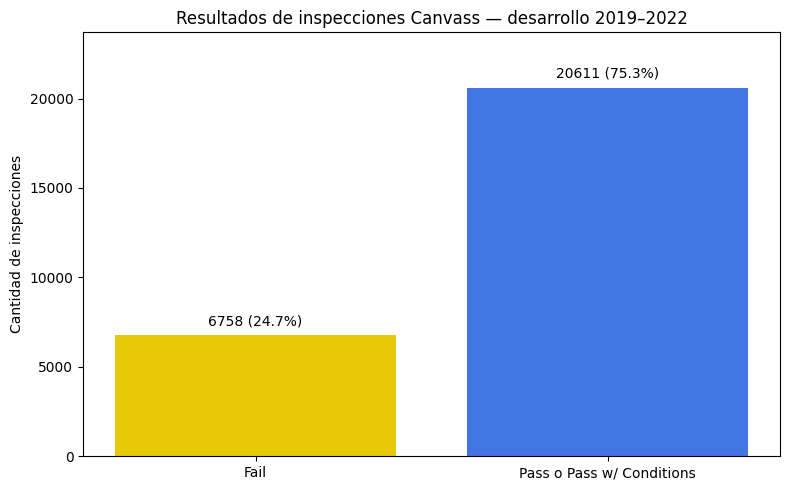

In [23]:
tabla_resultado = (
    desarrollo["resultado"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename_axis("resultado")
    .reset_index(name="n"))

tabla_resultado["porcentaje"] = (
    tabla_resultado["n"]
    / tabla_resultado["n"].sum()
    * 100)

tabla_resultado["significado"] = (
    tabla_resultado["resultado"].map({
        0: "Fail",
        1: "Pass o Pass w/ Conditions"
    }))
print(tabla_resultado.round(2).to_string(index=False))


# GRAFICARMENTE:
fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(
    tabla_resultado["significado"],
    tabla_resultado["n"],
    color=["#E7C907", "#4275E4"])

etiquetas = [
    f"{n} ({porcentaje:.1f}%)"
    for n, porcentaje in zip(
        tabla_resultado["n"],
        tabla_resultado["porcentaje"]
    )
]

ax.bar_label(barras, labels=etiquetas, padding=5)
ax.set_ylabel("Cantidad de inspecciones")
ax.set_title("Resultados de inspecciones Canvass — desarrollo 2019–2022")
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

Se puede observar un desbalanceo de clases (3:1), debemos considerar esto al momento implementar los distintos modelos.

Distribución Tipo de establecimiento

Inspecciones por tipo de establecimiento:
tipo_establecimiento
Restaurante                     18738
Escuela                          3227
Almacén                          2525
Cuidado infantil                 1224
Salud y adulto mayor              651
Panadería                         408
Catering y cocina compartida      385
Otro                              197
Desconocido                        14
Name: count, dtype: Int64


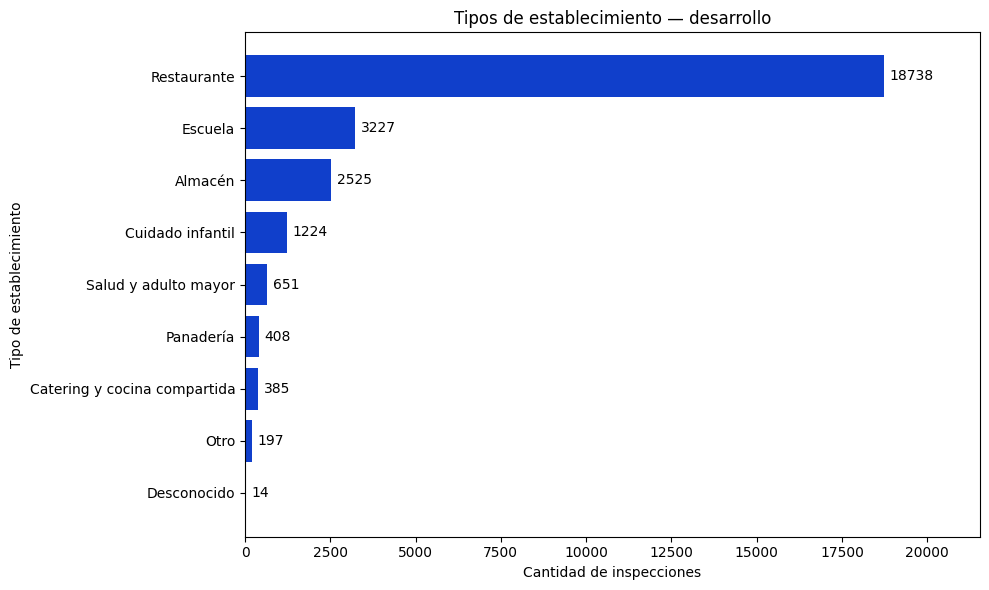

In [24]:
tipo = (desarrollo["tipo_establecimiento"].astype("string").fillna("Desconocido"))

frecuencias_tipo = tipo.value_counts()

print("Inspecciones por tipo de establecimiento:")
print(frecuencias_tipo)


# GRÁFICO #
fig, ax = plt.subplots(figsize=(10, 6))
barras = ax.barh(
    frecuencias_tipo.index,
    frecuencias_tipo.values,
    color="#103FCB")

ax.bar_label(barras, padding=4)
ax.invert_yaxis()
ax.margins(x=0.15)

ax.set_xlabel("Cantidad de inspecciones")
ax.set_ylabel("Tipo de establecimiento")
ax.set_title("Tipos de establecimiento — desarrollo")

plt.tight_layout()
plt.show()

Tipo de estableciminento - respuesta

tipo_establecimiento
Restaurante                     24.40
Escuela                         25.50
Almacén                         29.23
Cuidado infantil                19.28
Salud y adulto mayor            25.04
Panadería                       30.39
Catering y cocina compartida    16.36
Otro                            17.77
Desconocido                     21.43
Name: Porcentaje Fail, dtype: float64


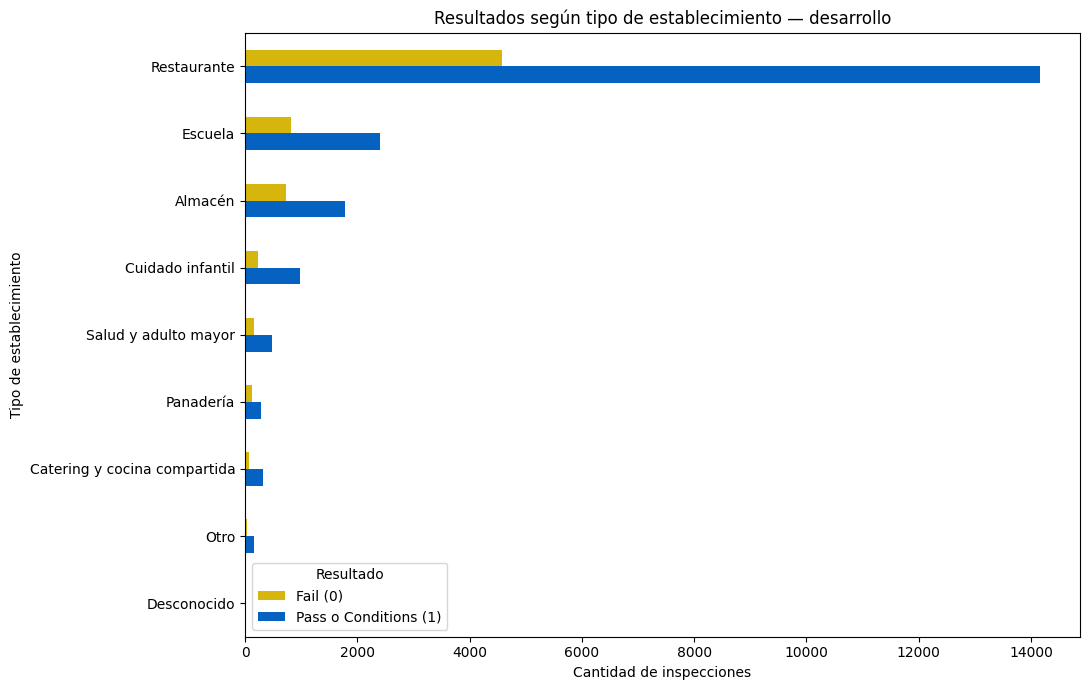

In [25]:
tipo_resultado = pd.crosstab(
    tipo,
    desarrollo["resultado"]
).reindex(
    index=frecuencias_tipo.index,
    columns=[0, 1],
    fill_value=0
)

tipo_resultado.columns = [
    "Fail (0)",
    "Pass o Conditions (1)"
]

tipo_resultado["Total"] = (
    tipo_resultado["Fail (0)"]
    + tipo_resultado["Pass o Conditions (1)"]
)

tipo_resultado["Porcentaje Fail"] = (
    tipo_resultado["Fail (0)"]
    / tipo_resultado["Total"]
    * 100
)

print(tipo_resultado["Porcentaje Fail"].round(2))


# GRÁFICO DE BARRAS AGRUPADAS #
ax = tipo_resultado[
    ["Fail (0)", "Pass o Conditions (1)"]
].plot(
    kind="barh",
    figsize=(11, 7),
    color=["#D6B50D", "#0562C0"]
)

ax.invert_yaxis()
ax.set_xlabel("Cantidad de inspecciones")
ax.set_ylabel("Tipo de establecimiento")
ax.set_title("Resultados según tipo de establecimiento — desarrollo")
ax.legend(title="Resultado")

plt.tight_layout()
plt.show()

Se puede observar que cada tipo de establecimiento tiene entre un $(15\%,30\%)$ de proporción de fail.

Riesgo previo

Inspecciones por riesgo previo:
riesgo_previo
0     8902
1    16100
2     2158
3      209
Name: count, dtype: Int64


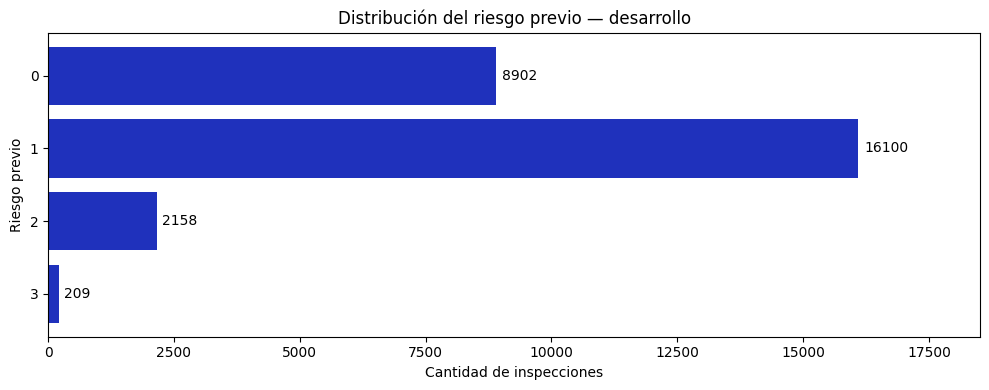

In [26]:
riesgo = (
    desarrollo["riesgo_previo"]
    .astype("string")
    .fillna("Sin riesgo previo disponible"))

frecuencias_riesgo = (
    riesgo.value_counts()
    .sort_index())

print("Inspecciones por riesgo previo:")
print(frecuencias_riesgo)


# GRÁFICO #
fig, ax = plt.subplots(figsize=(10, 4))

barras = ax.barh(
    frecuencias_riesgo.index,
    frecuencias_riesgo.values,
    color="#1F31BC"
)

ax.bar_label(barras, padding=4)
ax.invert_yaxis()
ax.margins(x=0.15)

ax.set_xlabel("Cantidad de inspecciones")
ax.set_ylabel("Riesgo previo")
ax.set_title("Distribución del riesgo previo — desarrollo")

plt.tight_layout()
plt.show()

La categoría de riesgo previo alto concentra la mayor cantidad de inspecciones de desarrollo, tambien llama la atención que la segunda mayoría corresponde a locales que no cuenta con un registro previo de riesgo.

Riesgo previo y resultado

riesgo_previo
0    23.67
1    25.57
2    22.29
3    25.36
Name: Porcentaje Fail, dtype: float64


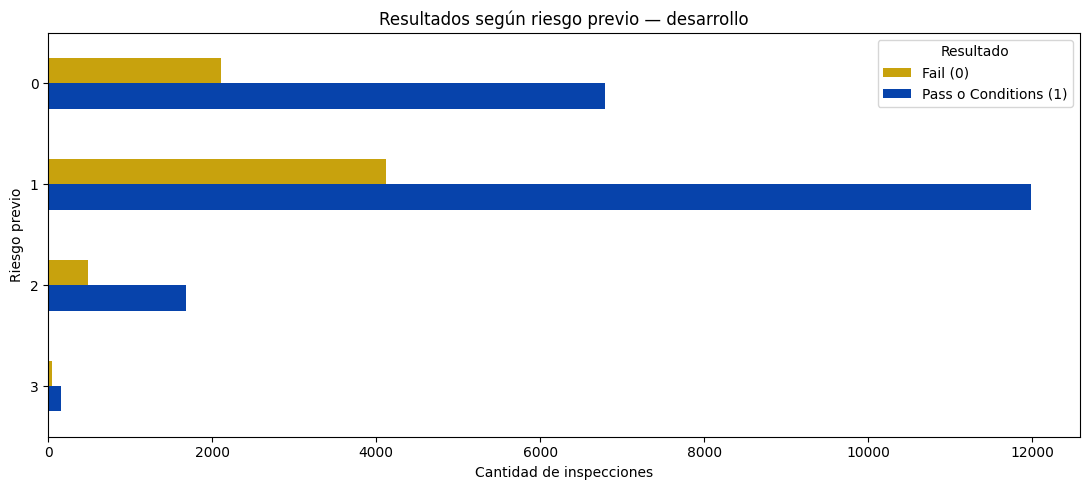

In [27]:
riesgo_resultado = pd.crosstab(
    riesgo,
    desarrollo["resultado"]
).reindex(
    index=frecuencias_riesgo.index,
    columns=[0, 1],
    fill_value=0
)

riesgo_resultado.columns = [
    "Fail (0)",
    "Pass o Conditions (1)"
]

riesgo_resultado["Total"] = (
    riesgo_resultado["Fail (0)"]
    + riesgo_resultado["Pass o Conditions (1)"]
)

riesgo_resultado["Porcentaje Fail"] = (
    riesgo_resultado["Fail (0)"]
    / riesgo_resultado["Total"]
    * 100
)

print(riesgo_resultado["Porcentaje Fail"].round(2))


# GRÁFICO DE BARRAS AGRUPADAS #
ax = riesgo_resultado[
    ["Fail (0)", "Pass o Conditions (1)"]
].plot(
    kind="barh",
    figsize=(11, 5),
    color=["#C8A20D", "#0743AB"]
)

ax.invert_yaxis()
ax.set_xlabel("Cantidad de inspecciones")
ax.set_ylabel("Riesgo previo")
ax.set_title("Resultados según riesgo previo — desarrollo")
ax.legend(title="Resultado")

plt.tight_layout()
plt.show()

La proporción de fails dentro de cada categoria corresponde (4:1)

Box-plot de las variables numericas sepando por tipo de resultado.

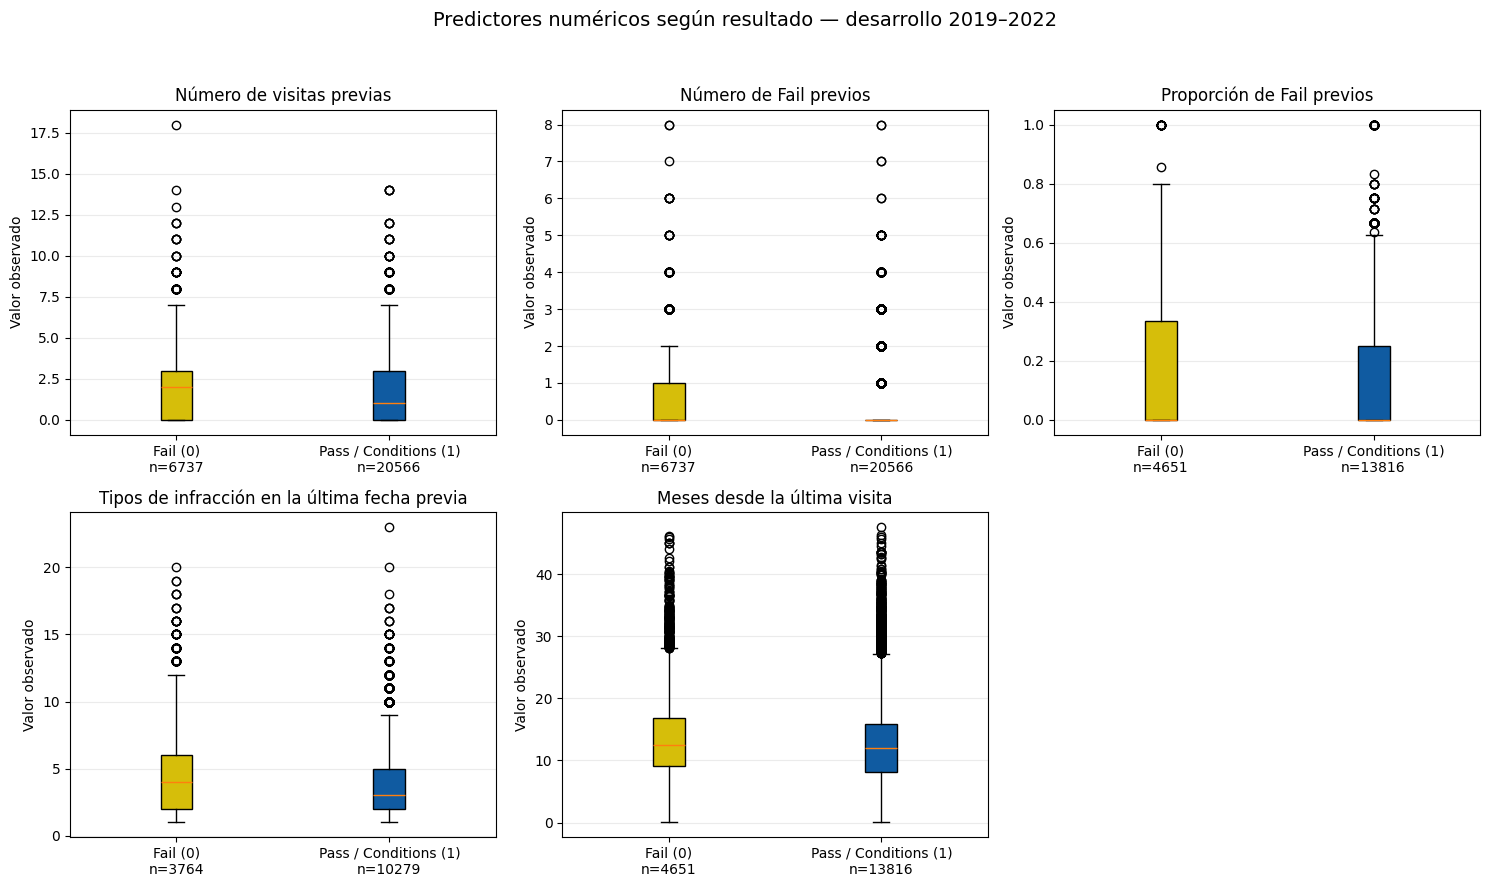

In [28]:
titulos = {
    "n_visitas_previas": "Número de visitas previas",
    "n_fail_previos": "Número de Fail previos",
    "prop_fail_previa": "Proporción de Fail previos",
    "meses_desde_ultima_visita": "Meses desde la última visita",
    "n_tipos_infraccion_previos": "Tipos de infracción en la última fecha previa"
}

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, variable in zip(axes.ravel(), numericas):

    # Valores disponibles entre las inspecciones con Fail.
    valores_fail = (
        desarrollo.loc[
            desarrollo["resultado"].eq(0),
            variable
        ]
        .dropna()
        .astype(float)
        .to_numpy()
    )

    # Valores disponibles entre las inspecciones aprobadas.
    valores_pass = (
        desarrollo.loc[
            desarrollo["resultado"].eq(1),
            variable
        ]
        .dropna()
        .astype(float)
        .to_numpy()
    )

    cajas = ax.boxplot(
        [valores_fail, valores_pass],
        patch_artist=True,
        showfliers=True
    )

    # Mantener los colores de los gráficos anteriores.
    for caja, color in zip(
        cajas["boxes"],
        ["#D6BE0A", "#105BA1"]
    ):
        caja.set_facecolor(color)

    ax.set_xticks(
        [1, 2],
        [
            f"Fail (0)\nn={len(valores_fail)}",
            f"Pass / Conditions (1)\nn={len(valores_pass)}"
        ]
    )

    ax.set_title(titulos[variable])
    ax.set_ylabel("Valor observado")
    ax.grid(axis="y", alpha=0.25)

# Ocultar el sexto panel, que queda vacío.
for ax in axes.ravel()[len(numericas):]:
    ax.set_visible(False)

fig.suptitle(
    "Predictores numéricos según resultado — desarrollo 2019–2022",
    fontsize=14
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

Resumen númerico de los box-plot anteriores

In [29]:
numericas = [
    "n_visitas_previas",
    "n_fail_previos",
    "prop_fail_previa",
    "n_tipos_infraccion_previos",
    "meses_desde_ultima_visita"
]

resumen_numericas = (
    desarrollo[numericas]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99])
    .T
    .rename(columns={
        "count": "n_disponibles",
        "mean": "media",
        "std": "desv_estandar",
        "50%": "mediana"
    })
)

resumen_numericas["n_faltantes"] = (
    desarrollo[numericas].isna().sum()
)

print(resumen_numericas.round(3).to_string())

                            n_disponibles  media  desv_estandar    min    25%  mediana     75%   95%     99%   max  n_faltantes
n_visitas_previas                 27303.0   1.72          1.739    0.0    0.0      1.0     3.0   5.0     7.0  18.0           66
n_fail_previos                    27303.0  0.325          0.675    0.0    0.0      0.0     0.0   2.0     3.0   8.0           66
prop_fail_previa                  18467.0  0.136          0.201    0.0    0.0      0.0   0.333   0.5   0.667   1.0         8902
n_tipos_infraccion_previos        14043.0  4.014          2.835    1.0    2.0      3.0     5.0  10.0    13.0  23.0        13326
meses_desde_ultima_visita         18467.0  12.55          7.101  0.033  8.433   12.133  16.067  25.6  34.067  47.6         8902


Se analiza la proporción de fails dentro de aquellos locales que fueron identificados, que tuvieron o no una visita previa y locales que no pudieron ser identificados.

                grupo_historia  n_inspecciones  n_fail  porcentaje_muestra  porcentaje_fail
           Con visitas previas           18467    4651               67.47            25.19
Sin visitas previas observadas            8836    2086               32.28            23.61
        Local no identificable              66      21                0.24            31.82


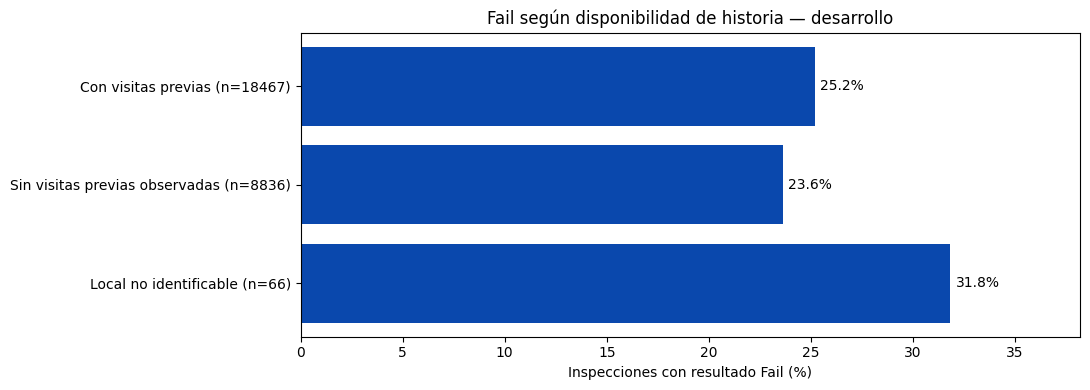

In [30]:
historia = desarrollo[["id_local", "n_visitas_previas", "resultado"]].copy()

historia["grupo_historia"] = "Antecedentes no calculables"

historia.loc[
    historia["n_visitas_previas"].eq(0).fillna(False),
    "grupo_historia"
] = "Sin visitas previas observadas"

historia.loc[
    historia["n_visitas_previas"].gt(0).fillna(False),
    "grupo_historia"
] = "Con visitas previas"

historia.loc[
    historia["id_local"].isna(),
    "grupo_historia"
] = "Local no identificable"


# RESUMIR CADA GRUPO #
tabla_historia = (
    historia
    .groupby("grupo_historia", as_index=False)
    .agg(
        n_inspecciones=("resultado", "size"),
        n_fail=("resultado", lambda x: x.eq(0).sum())
    )
    .sort_values("n_inspecciones", ascending=False)
)

tabla_historia["porcentaje_muestra"] = (
    tabla_historia["n_inspecciones"]
    / len(desarrollo)
    * 100
)

tabla_historia["porcentaje_fail"] = (
    tabla_historia["n_fail"]
    / tabla_historia["n_inspecciones"]
    * 100
)
print(tabla_historia.round(2).to_string(index=False))


# GRÁFICO #
etiquetas = [
    f"{grupo} (n={n})"
    for grupo, n in zip(
        tabla_historia["grupo_historia"],
        tabla_historia["n_inspecciones"]
    )
]

fig, ax = plt.subplots(figsize=(11, 4))

barras = ax.barh(
    etiquetas,
    tabla_historia["porcentaje_fail"],
    color="#0A48AD"
)

ax.bar_label(
    barras,
    labels=[
        f"{valor:.1f}%"
        for valor in tabla_historia["porcentaje_fail"]
    ],
    padding=4
)

ax.invert_yaxis()
ax.margins(x=0.20)
ax.set_xlabel("Inspecciones con resultado Fail (%)")
ax.set_title("Fail según disponibilidad de historia — desarrollo")

plt.tight_layout()
plt.show()

Podemos notar que la muestra de desarrollo tiene un $67.47\%$ de muestras identificadas de forma única y con visita previas. En proporción aquellos locales que no lograron ser identificados de forma única presentan la mayor proporción de fail.

Analizar la cantidad de inspecciones por año durante el periodo de 2019 a 2024 y calcular la proporción de fail, analizando su evolución temporal.

 anio  n_inspecciones  n_fail  porcentaje_fail
 2019            8343    1866            22.37
 2020            6162    1550            25.15
 2021            6230    1532            24.59
 2022            6634    1810            27.28


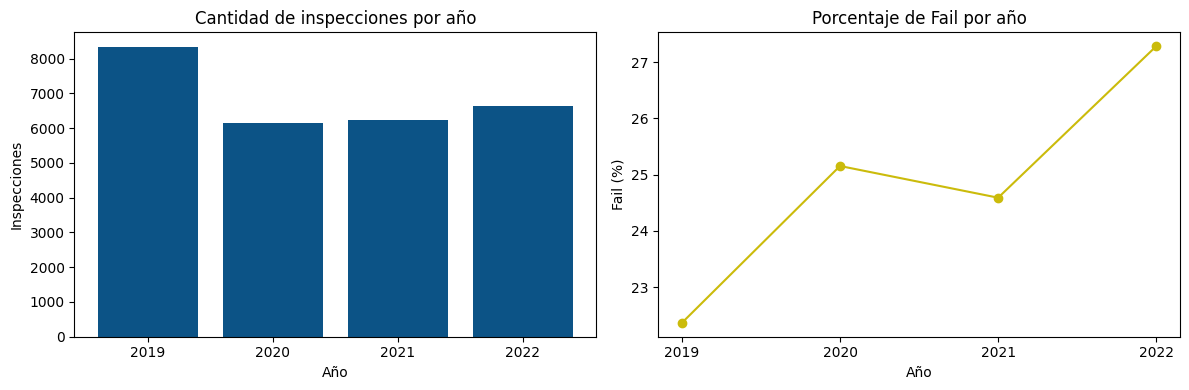

In [31]:
resumen_anual = (
    desarrollo.assign(
        anio=desarrollo["inspection_date"].dt.year
    )
    .groupby("anio", as_index=False)
    .agg(
        n_inspecciones=("resultado", "size"),
        n_fail=("resultado", lambda x: x.eq(0).sum())
    ))

resumen_anual["porcentaje_fail"] = (
    resumen_anual["n_fail"]
    / resumen_anual["n_inspecciones"]
    * 100)
print(resumen_anual.round(2).to_string(index=False))


# GRÁFICOS #
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(
    resumen_anual["anio"],
    resumen_anual["n_inspecciones"],
    color="#0C5386"
)

axes[0].set_title("Cantidad de inspecciones por año")
axes[0].set_ylabel("Inspecciones")

axes[1].plot(
    resumen_anual["anio"],
    resumen_anual["porcentaje_fail"],
    marker="o",
    color="#CBBB0B"
)

axes[1].set_title("Porcentaje de Fail por año")
axes[1].set_ylabel("Fail (%)")

for ax in axes:
    ax.set_xlabel("Año")
    ax.set_xticks(resumen_anual["anio"])

plt.tight_layout()
plt.show()

Se puede observar que el año 2019 presenta la mayor cantidad de inspecciones, sin embargo tiene la menor proporción de fail. Tambien se puede apreciar una tendencia al alza de la proporción de fail a partir del 2019.

Locales identificados: 12303
Locales con una sola inspección: 4412
Locales con más de una inspección: 7891

Resumen de inspecciones por local:
count    12303.00
mean         2.22
std          1.15
min          1.00
25%          1.00
50%          2.00
75%          3.00
max          8.00
Name: n_inspecciones, dtype: float64

Distribución:
 n_inspecciones_por_local  n_locales  porcentaje_locales
                        1       4412               35.86
                        2       3108               25.26
                        3       2668               21.69
                        4       1958               15.91
                        5        116                0.94
                        6         30                0.24
                        7          9                0.07
                        8          2                0.02


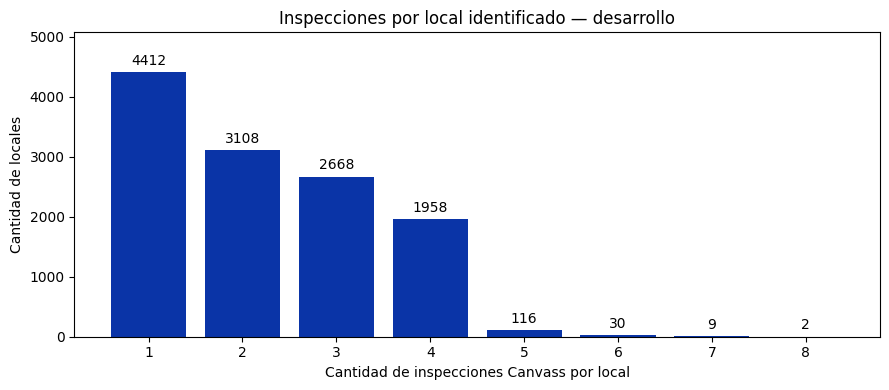

In [32]:
inspecciones_por_local = (
    desarrollo.loc[
        desarrollo["id_local"].notna()
    ]
    .groupby("id_local")
    .size()
    .rename("n_inspecciones")
)

# RESUMEN #
print("Locales identificados:", len(inspecciones_por_local))
print(
    "Locales con una sola inspección:",
    inspecciones_por_local.eq(1).sum()
)

print(
    "Locales con más de una inspección:",
    inspecciones_por_local.gt(1).sum()
)

print("\nResumen de inspecciones por local:")
print(inspecciones_por_local.describe().round(2))


# DISTRIBUCIÓN #

tabla_repeticion = (
    inspecciones_por_local
    .value_counts()
    .sort_index()
    .rename_axis("n_inspecciones_por_local")
    .reset_index(name="n_locales")
)

tabla_repeticion["porcentaje_locales"] = (
    tabla_repeticion["n_locales"]
    / tabla_repeticion["n_locales"].sum()
    * 100
)

print("\nDistribución:")
print(tabla_repeticion.round(2).to_string(index=False))


# GRÁFICO #

fig, ax = plt.subplots(figsize=(9, 4))

barras = ax.bar(
    tabla_repeticion["n_inspecciones_por_local"],
    tabla_repeticion["n_locales"],
    color="#0A34A7"
)

ax.bar_label(barras, padding=3)
ax.margins(y=0.15)

ax.set_xticks(tabla_repeticion["n_inspecciones_por_local"])
ax.set_xlabel("Cantidad de inspecciones Canvass por local")
ax.set_ylabel("Cantidad de locales")
ax.set_title("Inspecciones por local identificado — desarrollo")

plt.tight_layout()
plt.show()

Considerando de 2019 a 2022 se lograron identificar $12.303$ locales unicos, donde el $35\%$ de ellos solo tuvo una inspección tipo canvas durante ese periodo. Tambien se puede observa que la  mediana es cercana a 2, lo cual indica que más de la mitad de los locales tuvieron inspecciones repetidas en la ventana de observacion.

Finalmente se tabula la cantidad de observaciones se quedaron excluidas del analisis luego de realizar supuestos y consideraciones de acuerdo al contexto.

In [33]:
tabla_flujo = pd.DataFrame({
    "etapa": [
        "Archivo original",
        "Después del filtro Illinois",
        "Después del filtro Chicago",
        "Canvass con cualquier resultado",
        "Canvass con resultado binario elegible"
    ],
    "n_inspecciones": [
        n_originales,
        n_illinois,
        n_chicago,
        n_canvass_todos,
        len(datos_canvass)
    ]
})

tabla_flujo["excluidas_en_etapa"] = (
    tabla_flujo["n_inspecciones"].shift(1)
    - tabla_flujo["n_inspecciones"]
).astype("Int64")

tabla_flujo["porcentaje_original"] = (
    tabla_flujo["n_inspecciones"]
    / n_originales
    * 100
)

print(tabla_flujo.round(2).to_string(index=False))

                                 etapa  n_inspecciones  excluidas_en_etapa  porcentaje_original
                      Archivo original          104468                <NA>               100.00
           Después del filtro Illinois          104424                  44                99.96
            Después del filtro Chicago          104311                 113                99.85
       Canvass con cualquier resultado           52603               51708                50.35
Canvass con resultado binario elegible           43216                9387                41.37


In [34]:
fechas = datos_canvass["inspection_date"]

fuera_periodo = (
    fechas.notna()
    & ~(
        fechas.ge("2019-01-01")
        & fechas.lt("2025-01-01")
    )
)

tabla_particiones = pd.DataFrame({
    "destino": [
        "Desarrollo: 2019–2022",
        "Reserva: 2023–2024",
        "Sin fecha",
        "Fecha fuera de 2019–2024"
    ],
    "n_inspecciones": [
        len(desarrollo),
        len(reserva),
        int(fechas.isna().sum()),
        int(fuera_periodo.sum())
    ]
})

tabla_particiones["porcentaje_base_analitica"] = (
    tabla_particiones["n_inspecciones"]
    / len(datos_canvass)
    * 100
)

assert (
    tabla_particiones["n_inspecciones"].sum()
    == len(datos_canvass)
), "Los conteos de las particiones no coinciden con la base analítica."

print(tabla_particiones.round(2).to_string(index=False))

                 destino  n_inspecciones  porcentaje_base_analitica
   Desarrollo: 2019–2022           27369                      63.33
      Reserva: 2023–2024           15847                      36.67
               Sin fecha               0                       0.00
Fecha fuera de 2019–2024               0                       0.00


Se observa que todas las observaciones de la base contienen una fecha de inspección y que todas corresponden fechas entre 2019 y 2024.

                            n_visitas_previas  n_fail_previos  \
n_visitas_previas                       1.000           0.639   
n_fail_previos                          0.639           1.000   
prop_fail_previa                        0.528           0.972   
n_tipos_infraccion_previos             -0.190          -0.081   
meses_desde_ultima_visita              -0.120          -0.010   

                            prop_fail_previa  n_tipos_infraccion_previos  \
n_visitas_previas                      0.528                      -0.190   
n_fail_previos                         0.972                      -0.081   
prop_fail_previa                       1.000                      -0.070   
n_tipos_infraccion_previos            -0.070                       1.000   
meses_desde_ultima_visita              0.012                       0.034   

                            meses_desde_ultima_visita  
n_visitas_previas                              -0.120  
n_fail_previos                          

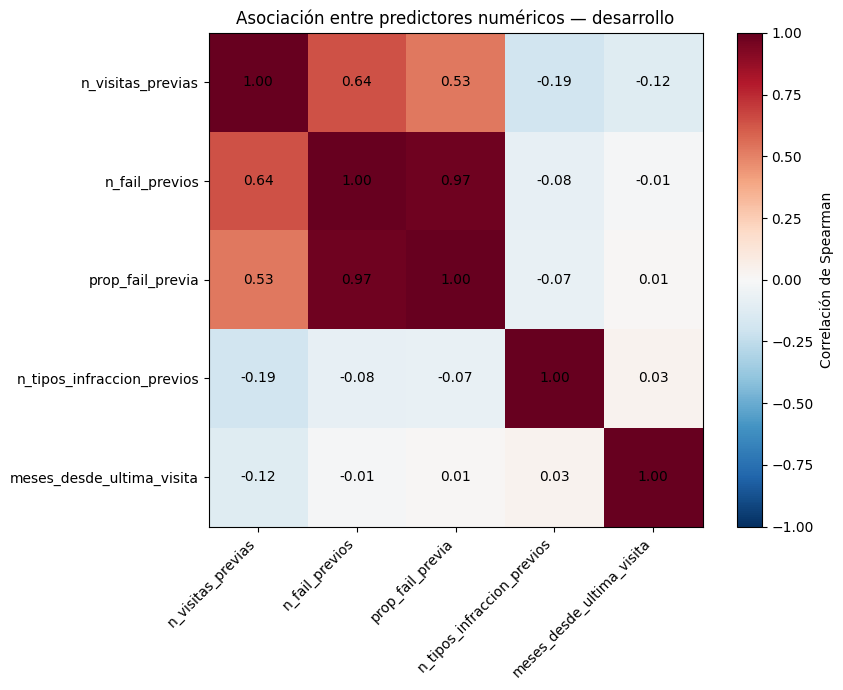

In [35]:
## correlaciones

correlaciones = desarrollo[numericas].corr(method="spearman")
print(correlaciones.round(3))

fig, ax = plt.subplots(figsize=(9, 7))
imagen = ax.imshow(
    correlaciones,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
)

ax.set_xticks(range(len(numericas)), numericas, rotation=45, ha="right")
ax.set_yticks(range(len(numericas)), numericas)

for i in range(len(numericas)):
    for j in range(len(numericas)):
        ax.text(
            j, i, f"{correlaciones.iloc[i, j]:.2f}",
            ha="center", va="center",
        )

fig.colorbar(imagen, ax=ax, label="Correlación de Spearman")
ax.set_title("Asociación entre predictores numéricos — desarrollo")
plt.tight_layout()
plt.show()

Se puede observar una alta correlación entre el numero de fail previos y la proporción fail previos, lo cual es bastante esperable, dado que una de ella se utilza para crear la otra.

# 5 M0 — Regresión Logística (BASE)

Consideramos este modelo como nuestra **referencia** para luego comparar si hay una mejora considerable con modelo más complejos que justifique el cambio, teniendo en cuenta la parsimonia. Para este modelo se utilizará una regresión logística simple, donde no se considerará posibles correlaciones entre covariables o penalización sobre alguna de ellas. Solamente realizamos un escalamientos de las variable númericas.

In [36]:
predictores = numericas + categoricas

# VALIDACIÓN TEMPORAL INTERNA #
predicciones_ventanas = []
modelos_logisticos = {}
tamanos_ventanas = []

for anio_validacion in [2020, 2021, 2022]:

    inicio_validacion = pd.Timestamp(anio_validacion, 1, 1)
    fin_validacion = pd.Timestamp(anio_validacion + 1, 1, 1)

    # Entrenar desde 2019 hasta el final del año anterior.
    entrenamiento = desarrollo.loc[
        desarrollo["inspection_date"].ge("2019-01-01")
        & desarrollo["inspection_date"].lt(inicio_validacion)
    ].copy()

    # Validar únicamente en el año correspondiente.
    validacion = desarrollo.loc[
        desarrollo["inspection_date"].ge(inicio_validacion)
        & desarrollo["inspection_date"].lt(fin_validacion)
    ].copy()

    if entrenamiento.empty or validacion.empty:
        raise ValueError(
            f"La ventana que valida en {anio_validacion} está vacía."
        )

    if not entrenamiento["resultado"].isin([0, 1]).all():
        raise ValueError("El entrenamiento contiene respuestas inválidas.")

    if not validacion["resultado"].isin([0, 1]).all():
        raise ValueError("La validación contiene respuestas inválidas.")

    if entrenamiento["resultado"].nunique() != 2:
        raise ValueError(
            f"Falta una clase en el entrenamiento de {anio_validacion}."
        )

    # Preparar entradas y respuesta.
    X_entrenamiento = preparar_X(entrenamiento)
    X_validacion = preparar_X(validacion)

    y_entrenamiento = entrenamiento["resultado"].astype(int)

    # Crear y ajustar todo el procedimiento con entrenamiento.
    modelo = crear_logistica()

    modelo.fit(X_entrenamiento, y_entrenamiento)

    # Identificar la columna correspondiente a Fail, cuyo código es 0.
    posicion_fail = int(
        np.flatnonzero(modelo.classes_ == 0)[0]
    )

    prob_fail = modelo.predict_proba(
        X_validacion
    )[:, posicion_fail]

    # Guardar las predicciones de las inspecciones validadas.
    salida = validacion[
        [
            "inspection_id",
            "id_local",
            "inspection_date",
            "resultado"
        ]
    ].copy()

    salida["anio_validacion"] = anio_validacion
    salida["prob_fail"] = prob_fail

    predicciones_ventanas.append(salida)

    # Guardar cada modelo ajustado.
    modelos_logisticos[anio_validacion] = modelo

    tamanos_ventanas.append({
        "anio_validacion": anio_validacion,
        "entrenamiento": f"2019–{anio_validacion - 1}",
        "n_entrenamiento": len(entrenamiento),
        "n_validacion": len(validacion)
    })


# REUNIR LAS PREDICCIONES DE VALIDACIÓN #
predicciones_logistica = pd.concat(
    predicciones_ventanas,
    ignore_index=True
)

tabla_ventanas = pd.DataFrame(tamanos_ventanas)

print(tabla_ventanas.to_string(index=False))

c:\Users\gutie\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
c:\Users\gutie\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


 anio_validacion entrenamiento  n_entrenamiento  n_validacion
            2020     2019–2019             8343          6162
            2021     2019–2020            14505          6230
            2022     2019–2021            20735          6634


c:\Users\gutie\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


Métricas por ventana:
 anio_validacion  n_validacion  prevalencia_fail  umbral_fail  log_loss  auc_roc_fail  sensibilidad_fail  precision_fail  n_fail_predichos
            2020          6162            0.2515         0.25    0.5710        0.5935             0.5548          0.3191              2695
            2021          6230            0.2459         0.25    0.5443        0.6078             0.4726          0.3270              2214
            2022          6634            0.2728         0.25    0.5755        0.6017             0.5028          0.3520              2585


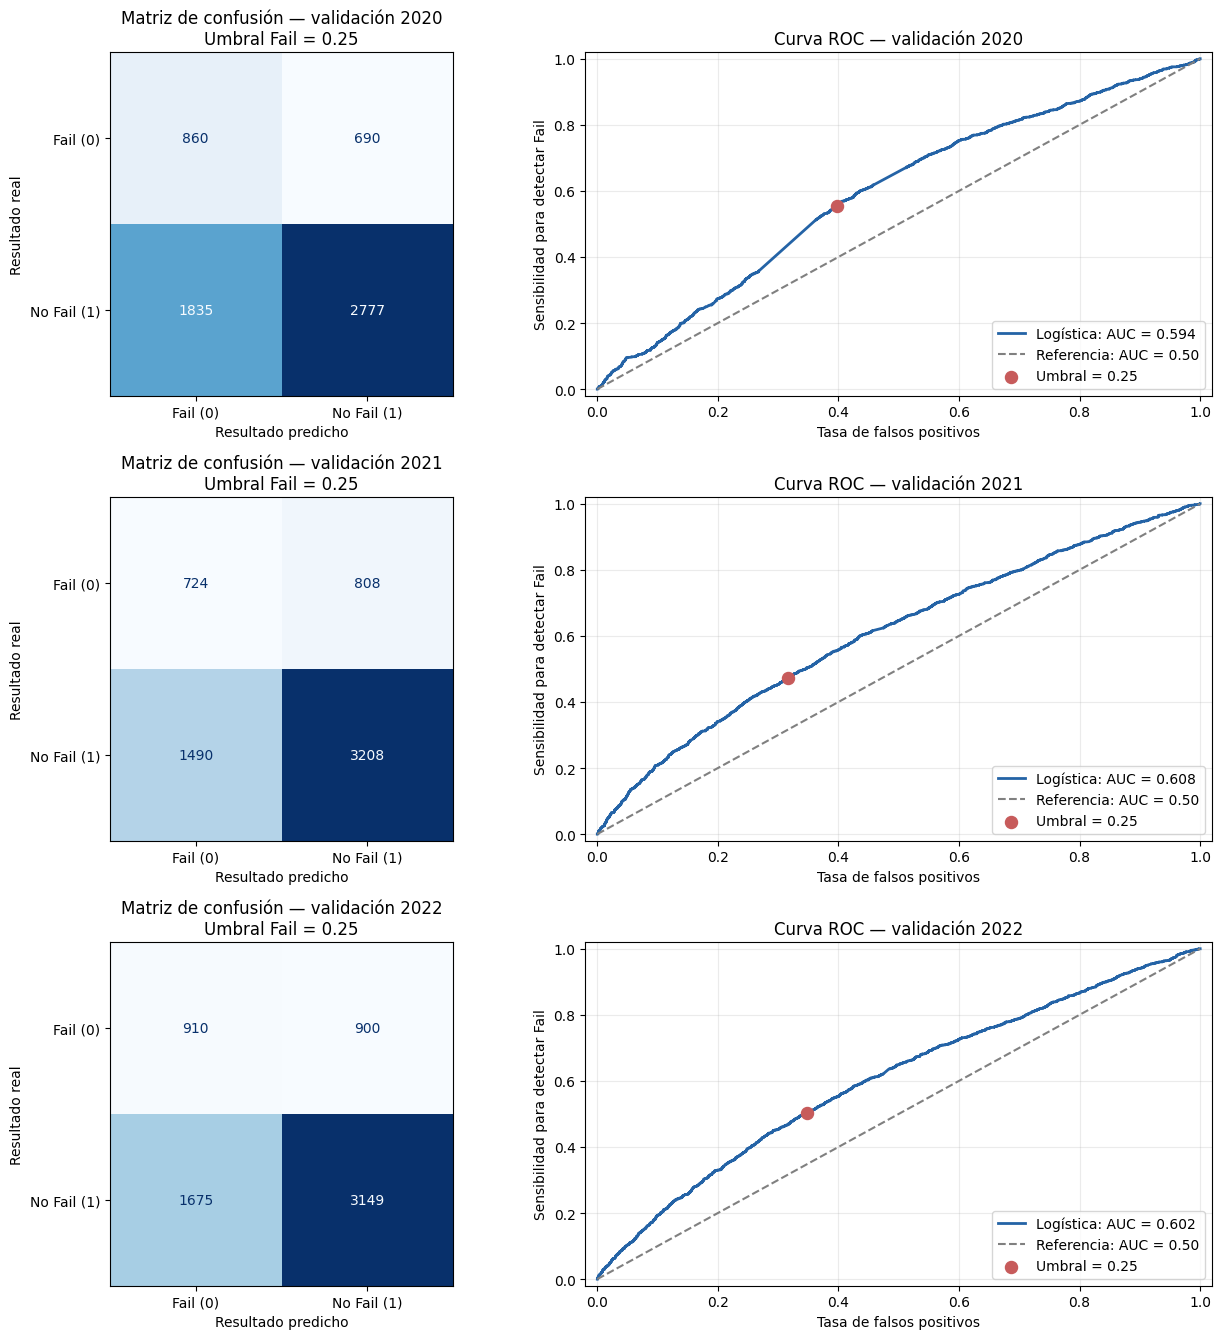


Resumen de validación:
log_loss_ponderado        0.5638
auc_roc_promedio_anual    0.6010
dtype: float64


In [38]:
# UMBRAL PARA CLASIFICAR COMO FAIL #
umbral = 0.25

# CALCULAR LAS MÉTRICAS Y MATRICES #
metricas_logistica, matrices_logistica = evaluar_umbral(
    predicciones_logistica,
    umbral=umbral
)

print("Métricas por ventana:")
print(metricas_logistica.round(4).to_string(index=False))


# GRÁFICOS POR VENTANA TEMPORAL #
anios = sorted(
    predicciones_logistica["anio_validacion"].unique()
)

fig, axes = plt.subplots(
    nrows=len(anios),
    ncols=2,
    figsize=(13, 4.5 * len(anios)),
    squeeze=False
)

for fila, anio in enumerate(anios):

    # Seleccionar las predicciones del año correspondiente.
    grupo = predicciones_logistica.loc[
        predicciones_logistica["anio_validacion"] == anio
    ]

    y_real = grupo["resultado"].to_numpy(dtype=int)
    prob_fail = grupo["prob_fail"].to_numpy(dtype=float)

    # Calcular nuevamente la clasificación con el umbral actual.
    y_pred = np.where(prob_fail >= umbral, 0, 1)

    # MATRIZ DE CONFUSIÓN #
    matriz = confusion_matrix(
        y_real,
        y_pred,
        labels=[0, 1]
    )

    visualizacion = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=["Fail (0)", "No Fail (1)"]
    )

    visualizacion.plot(
        ax=axes[fila, 0],
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    axes[fila, 0].set_title(
        f"Matriz de confusión — validación {anio}\n"
        f"Umbral Fail = {umbral:.2f}"
    )
    axes[fila, 0].set_xlabel("Resultado predicho")
    axes[fila, 0].set_ylabel("Resultado real")

    # CURVA ROC: FAIL COMO EVENTO DE INTERÉS #
    # Este indicador auxiliar no modifica la respuesta original.
    y_real_fail = (y_real == 0).astype(int)

    ax_roc = axes[fila, 1]

    if np.unique(y_real_fail).size == 2:

        fpr, tpr, _ = roc_curve(y_real_fail, prob_fail)
        auc = roc_auc_score(y_real_fail, prob_fail)

        ax_roc.plot(
            fpr, tpr,
            color="#2463A6",
            linewidth=2,
            label=f"Logística: AUC = {auc:.3f}"
        )

        ax_roc.plot(
            [0, 1], [0, 1],
            linestyle="--",
            color="gray",
            label="Referencia: AUC = 0.50"
        )

        # Ubicar en la curva el punto correspondiente al umbral.
        VP = matriz[0, 0]
        FN = matriz[0, 1]
        FP = matriz[1, 0]
        VN = matriz[1, 1]

        sensibilidad = VP / (VP + FN)
        tasa_falsos_positivos = FP / (FP + VN)

        ax_roc.scatter(
            tasa_falsos_positivos,
            sensibilidad,
            color="#C75B5B",
            s=75,
            zorder=3,
            label=f"Umbral = {umbral:.2f}"
        )

        ax_roc.legend(loc="lower right")

    else:
        ax_roc.text(
            0.5, 0.5,
            "ROC no definida: solo hay una clase",
            ha="center",
            va="center"
        )

    ax_roc.set_title(f"Curva ROC — validación {anio}")
    ax_roc.set_xlabel("Tasa de falsos positivos")
    ax_roc.set_ylabel("Sensibilidad para detectar Fail")
    ax_roc.set_xlim(-0.02, 1.02)
    ax_roc.set_ylim(-0.02, 1.02)
    ax_roc.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# RESUMEN DEL DESEMPEÑO PROBABILÍSTICO #
resumen_cv = pd.Series({
    "log_loss_ponderado": np.average(
        metricas_logistica["log_loss"],
        weights=metricas_logistica["n_validacion"]
    ),
    "auc_roc_promedio_anual": (
        metricas_logistica["auc_roc_fail"].mean()
    )
})

print("\nResumen de validación:")
print(resumen_cv.round(4))

c:\Users\gutie\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


                                         variable  coeficiente_fail  odds_ratio_fail
                                n_visitas_previas          0.083542         1.087131
                                   n_fail_previos          0.046729         1.047838
                                 prop_fail_previa          0.124383         1.132449
                       n_tipos_infraccion_previos          0.256539         1.292449
                        meses_desde_ultima_visita          0.091818         1.096165
               missingindicator_n_visitas_previas          0.012505         1.012584
                  missingindicator_n_fail_previos          0.012505         1.012584
                missingindicator_prop_fail_previa          0.072016         1.074672
      missingindicator_n_tipos_infraccion_previos         -0.097238         0.907340
       missingindicator_meses_desde_ultima_visita          0.072016         1.074672
tipo_establecimiento_Catering y cocina compartida         -0.6488

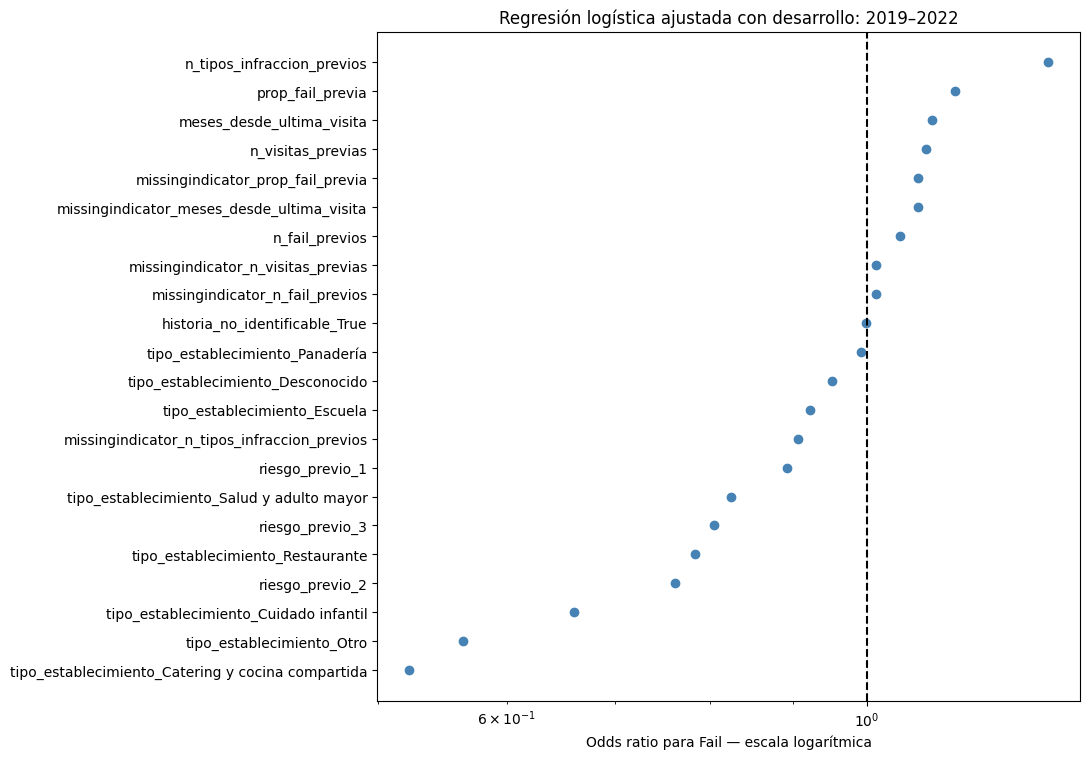

In [39]:
# 1. AJUSTAR EL MODELO CON TODO DESARROLLO #
# No utilizamos la reserva para construir este gráfico.
modelo_logistico_final = crear_logistica()

modelo_logistico_final.fit(
    preparar_X(desarrollo),
    desarrollo["resultado"].astype(int)
)

# 2. EXTRAER EL PREPROCESAMIENTO Y LA REGRESIÓN #
preprocesamiento = modelo_logistico_final.named_steps["preprocesamiento"]
logistica = modelo_logistico_final.named_steps["logistica"]

# Comprobar la codificación utilizada.
assert np.array_equal(logistica.classes_, [0, 1])

# Obtener los nombres de las columnas después de transformar los datos.
nombres = preprocesamiento.get_feature_names_out()

# Cambiamos el signo para interpretar los coeficientes respecto de Fail.
coeficientes_fail = -logistica.coef_[0]

tabla_or = pd.DataFrame({
    "variable": nombres,
    "coeficiente_fail": coeficientes_fail,
    "odds_ratio_fail": np.exp(coeficientes_fail)
})

# 3. PREPARAR LOS NOMBRES PARA MOSTRARLOS #
tabla_or["variable"] = (
    tabla_or["variable"]
    .str.replace("numericas__", "", regex=False)
    .str.replace("categoricas__", "", regex=False)
)

print(tabla_or.to_string(index=False))

# 4. GRAFICAR LOS ODDS RATIOS #
tabla_grafico = tabla_or.sort_values("odds_ratio_fail")

fig, ax = plt.subplots(
    figsize=(11, max(6, len(tabla_grafico) * 0.35))
)

ax.scatter(
    tabla_grafico["odds_ratio_fail"],
    tabla_grafico["variable"],
    color="steelblue"
)

# OR = 1 representa ausencia de cambio en los odds.
ax.axvline(1, color="black", linestyle="--")

ax.set_xscale("log")
ax.set_xlabel("Odds ratio para Fail — escala logarítmica")
ax.set_ylabel("")
ax.set_title("Regresión logística ajustada con desarrollo: 2019–2022")
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

# 6. M1 — Regresión Logística


Para el desarrollo de este modelo, se utiliza el conjunto correspondiente al período 2019-2022. Se consideran nueve predictores, los cuales se encuentran disponibles antes de cada inspección a la fecha.
Las variables se clasifican en dos grupos: numéricas y categóricas. Para las cuales, se realizan conversiones necesarias para cada una en su contexto.

In [ ]:
m1_desarrollo = desarrollo.copy()
m1_desarrollo["anio_m1"] = m1_desarrollo["inspection_date"].dt.year
m1_desarrollo["mes_m1"] = m1_desarrollo["inspection_date"].dt.month.astype("string")
m1_desarrollo["riesgo_previo"] = m1_desarrollo["riesgo_previo"].astype(str)

numericas_m1 = ["n_visitas_previas", "n_fail_previos", "prop_fail_previa",
"n_tipos_infraccion_previos","meses_desde_ultima_visita", "historia_no_identificable",]

categoricas_m1 = ["tipo_establecimiento","mes_m1", "riesgo_previo"]
predictores_m1 = numericas_m1 + categoricas_m1 

#números de pandas a decimal
for columna in numericas_m1:
    m1_desarrollo[columna]= pd.to_numeric(m1_desarrollo[columna], errors = "coerce").astype("float64")

for columna in categoricas_m1:
    m1_desarrollo[columna] = m1_desarrollo[columna].astype("object")
    m1_desarrollo[columna] = m1_desarrollo[columna].where(m1_desarrollo[columna].notna(), np.nan)

Se realiza el entrenamiento 

In [ ]:
preprocesamiento_m1 = ColumnTransformer(
    transformers=[
        ("numericas", Pipeline([
            ("imputar", SimpleImputer(
                strategy="median",
                add_indicator=True,
                keep_empty_features=True
            )),
            ("estandarizar", StandardScaler()),
        ]), numericas_m1),

        ("categoricas", OneHotEncoder(
            handle_unknown="ignore"
        ), categoricas_m1),
    ],
    remainder="drop",
)

def construir_m1(penalizacion, C=1.0):
    C_ajustado = np.inf if penalizacion is None else C
    return Pipeline([
        ("preprocesar", preprocesamiento_m1),
        ("logistica", LogisticRegression(
            C=C_ajustado,
            l1_ratio = 0,
            max_iter=3000,
            solver="lbfgs"
        )),
    ])

## 6.2 Entrenamiento y validación

Se realiza el entrenamiento y validación de la base de datos, en las 3 ventanas temporales anteriormente mencionadas.


In [ ]:
ventanas_m1 = [(2019, 2020), (2020, 2021), (2021, 2022)]
configuraciones_m1 = [
    ("Sin penalizacion", None, 1.0),
    ("L2 (C=0.001)", "l2", 0.001),
    ("L2 (C=0.01)", "l2", 0.01),
    ("L2 (C=1)", "l2", 1.0),
    ("L2 (C=10)", "l2", 10.0),
]

resultados_m1 = []
for etiqueta, penalizacion, C in configuraciones_m1:
    for ultimo_anio_entrenar, anio_validar in ventanas_m1:
        entrenamiento = m1_desarrollo[m1_desarrollo["anio_m1"] <= ultimo_anio_entrenar]
        validacion = m1_desarrollo[m1_desarrollo["anio_m1"] == anio_validar]

        X_train = entrenamiento[predictores_m1]
        y_train = entrenamiento["resultado"].astype(int)
        X_val = validacion[predictores_m1]
        y_val = validacion["resultado"].astype(int)
        assert len(X_train) and len(X_val), "Alguna ventana no tiene observaciones"
        assert y_train.nunique() == 2, "El entrenamiento necesita ambas clases"

        modelo = construir_m1(penalizacion, C)
        modelo.fit(X_train, y_train)
        probas = modelo.predict_proba(X_val)  
        clases = modelo.named_steps["logistica"].classes_
        indice_fail = np.where(clases == 0)[0][0]
        p_fail = probas[:, indice_fail]  
        y_es_fail = (y_val == 0).astype(int)

        resultados_m1.append({
            "configuracion": etiqueta,
            "penalizacion": "sin" if penalizacion is None else penalizacion,
            "C": C,
            "entrenamiento_hasta": ultimo_anio_entrenar,
            "validacion": anio_validar,
            "n_entrenamiento": len(y_train),
            "n_validacion": len(y_val),
            "log_loss": log_loss(y_val, probas, labels=clases),
            "brier_fail": brier_score_loss(y_es_fail, p_fail),
            "auc_fail": roc_auc_score(y_es_fail, p_fail),
        })
resultados_m1 = pd.DataFrame(resultados_m1)

resultados_m1 = resultados_m1.sort_values(
    by="auc_fail",
    ascending=False
)

print(
    resultados_m1[
        ["configuracion", "validacion", "n_validacion",
         "log_loss", "brier_fail", "auc_fail"]
    ].round(4).to_string(index=False)
)


c:\Users\Graciela\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
c:\Users\Graciela\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
c:\Users\Graciela\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


   configuracion  validacion  n_validacion  log_loss  brier_fail  auc_fail
    L2 (C=0.001)        2021          6230    0.5429      0.1797    0.6168
     L2 (C=0.01)        2021          6230    0.5433      0.1798    0.6115
    L2 (C=0.001)        2020          6162    0.5535      0.1843    0.6082
        L2 (C=1)        2021          6230    0.5455      0.1806    0.6050
       L2 (C=10)        2021          6230    0.5455      0.1806    0.6049
Sin penalizacion        2021          6230    0.5455      0.1806    0.6049
    L2 (C=0.001)        2022          6634    0.5747      0.1937    0.6036
     L2 (C=0.01)        2022          6634    0.5746      0.1936    0.6029
        L2 (C=1)        2022          6634    0.5751      0.1937    0.6024
Sin penalizacion        2022          6634    0.5751      0.1937    0.6023
       L2 (C=10)        2022          6634    0.5751      0.1937    0.6023
     L2 (C=0.01)        2020          6162    0.5621      0.1875    0.5963
        L2 (C=1)        2

Considerando el mejor AUC, se obtiene que la mejor configuración es la penalización L2 con un C = 0.01. con un AUC de 0.62 aproximadamente. 

In [ ]:
# RESUMEN DE VALIDACIÓN #

comparacion_m1 = (
    resultados_m1
    .groupby("configuracion", as_index=False)
    .agg(
        auc_medio=("auc_fail", "mean"),
        log_loss_medio=("log_loss", "mean"),
        brier_medio=("brier_fail", "mean")
    )
    .sort_values("auc_medio", ascending=False)
)

display(comparacion_m1.round(4))

# SELECCIÓN DE CONFIGURACIÓN #

mejor_etiqueta = comparacion_m1.iloc[0]["configuracion"]

mejor_cfg = next(
    c for c in configuraciones_m1
    if c[0] == mejor_etiqueta
)

print("Mejor configuración:", mejor_etiqueta)

# AJUSTE FINAL #

modelo_m1_final = construir_m1(
    mejor_cfg[1],
    mejor_cfg[2]
)

modelo_m1_final.fit(
    m1_desarrollo[predictores_m1],
    m1_desarrollo["resultado"].astype(int)
)

print("M1 ajustado con desarrollo 2019-2022")

,configuracion,auc_medio,log_loss_medio,brier_medio
0,L2 (C=0.01),0.6035,0.5600,0.1870
1,L2 (C=0.1),0.5980,0.5648,0.1888
2,L2 (C=1),0.5970,0.5661,0.1893
3,L2 (C=10),0.5968,0.5668,0.1895
4,Sin penalizacion,0.5966,0.5670,0.1896


Mejor configuración: L2 (C=0.01)
M1 ajustado con desarrollo 2019-2022


## 6.3  Implementación del modelo

Se aplica el modelo con la configuración establecida en validación; y se realiza la matriz de confusión para cada una de las ventanas temporales, en conjunto con los graficos de la curva roc respectiva.

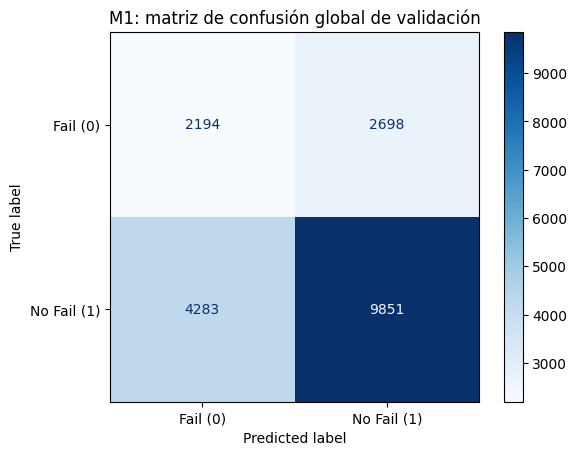

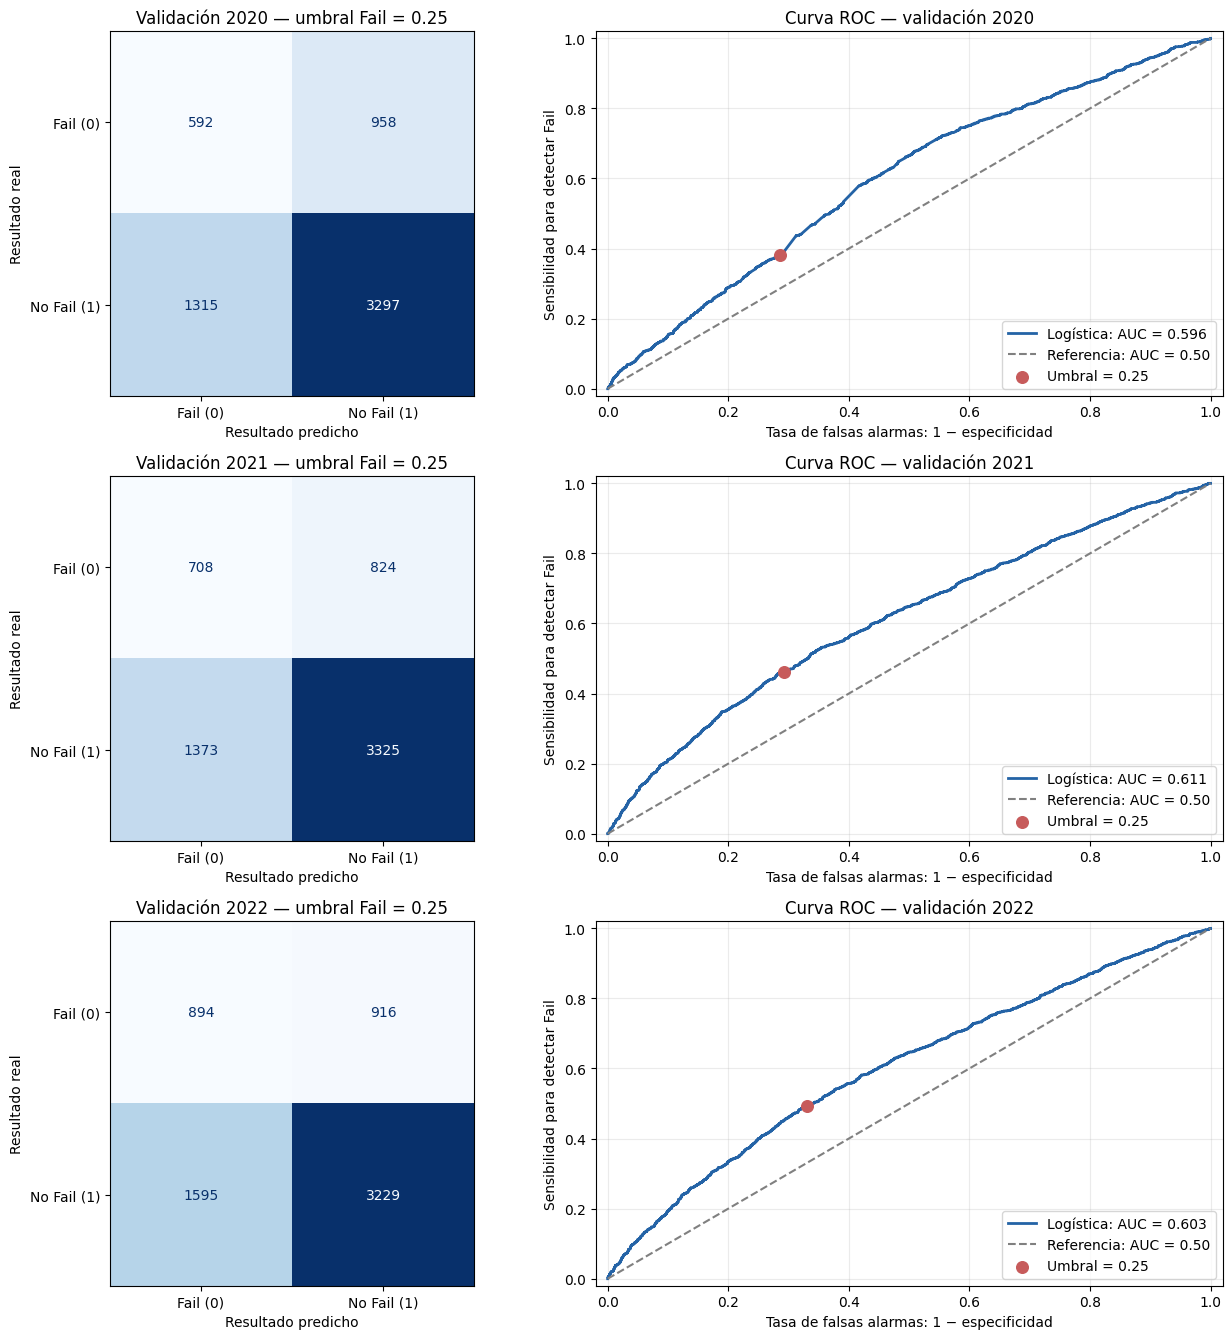

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

# PREDICCIONES DE VALIDACIÓN #

predicciones_m1 = []

for ultimo_anio, anio_validar in ventanas_m1:

    train = m1_desarrollo[
        m1_desarrollo["anio_m1"] <= ultimo_anio
    ]

    val = m1_desarrollo[
        m1_desarrollo["anio_m1"] == anio_validar
    ]

    modelo = construir_m1(
        mejor_cfg[1],
        mejor_cfg[2]
    )

    modelo.fit(
        train[predictores_m1],
        train["resultado"].astype(int)
    )

    clases = modelo.named_steps["logistica"].classes_
    indice_fail = np.where(clases == 0)[0][0]

    p_fail = modelo.predict_proba(
        val[predictores_m1]
    )[:, indice_fail]

    predicciones_m1.append(pd.DataFrame({
        "anio": anio_validar,
        "real": val["resultado"].astype(int).to_numpy(),
        "p_fail": p_fail
    }))

predicciones_m1 = pd.concat(
    predicciones_m1,
    ignore_index=True
)


# MATRIZ DE CONFUSIÓN GLOBAL DE VALIDACIÓN #

umbral = 0.25

predicciones_m1["predicho"] = np.where(
    predicciones_m1["p_fail"] >= umbral,
    0,   # Fail
    1    # No Fail
)

matriz_m1 = confusion_matrix(
    predicciones_m1["real"],
    predicciones_m1["predicho"],
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_m1,
    display_labels=["Fail (0)", "No Fail (1)"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("M1: matriz de confusión global de validación")
plt.show()


# GRÁFICOS POR VENTANA TEMPORAL #

anios = sorted(predicciones_m1["anio"].unique())

fig, axes = plt.subplots(
    nrows=len(anios),
    ncols=2,
    figsize=(13, 4.5 * len(anios)),
    squeeze=False
)

for fila, anio in enumerate(anios):

    grupo = predicciones_m1.loc[
        predicciones_m1["anio"] == anio
    ]

    # MATRIZ DE CONFUSIÓN #

    matriz = confusion_matrix(
        grupo["real"],
        grupo["predicho"],
        labels=[0, 1]
    )

    visualizacion = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=[
            "Fail (0)",
            "No Fail (1)"
        ]
    )

    visualizacion.plot(
        ax=axes[fila, 0],
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    axes[fila, 0].set_title(
        f"Validación {anio} — umbral Fail = {umbral:.2f}"
    )

    axes[fila, 0].set_xlabel("Resultado predicho")
    axes[fila, 0].set_ylabel("Resultado real")


    # CURVA ROC: FAIL COMO EVENTO DE INTERÉS #

    # Variable auxiliar: 1 indica que ocurrió Fail.
    # No modifica la respuesta original.
    y_real_fail = (
        grupo["real"].eq(0)
        .astype(int)
        .to_numpy()
    )

    prob_fail = grupo["p_fail"].to_numpy(dtype=float)

    ax_roc = axes[fila, 1]

    if np.unique(y_real_fail).size == 2:

        fpr, tpr, _ = roc_curve(
            y_real_fail,
            prob_fail,
            pos_label=1
        )

        auc = roc_auc_score(
            y_real_fail,
            prob_fail
        )

        ax_roc.plot(
            fpr,
            tpr,
            color="#2463A6",
            linewidth=2,
            label=f"Logística: AUC = {auc:.3f}"
        )

        # Referencia de ausencia de discriminación
        ax_roc.plot(
            [0, 1],
            [0, 1],
            linestyle="--",
            color="gray",
            label="Referencia: AUC = 0.50"
        )


        # UBICAR EL UMBRAL ACTUAL SOBRE LA CURVA #

        # Orden de la matriz: Fail (0), No Fail (1)
        verdaderos_positivos = matriz[0, 0]
        falsos_negativos = matriz[0, 1]
        falsos_positivos = matriz[1, 0]
        verdaderos_negativos = matriz[1, 1]

        sensibilidad = (
            verdaderos_positivos
            / (verdaderos_positivos + falsos_negativos)
        )

        tasa_falsos_positivos = (
            falsos_positivos
            / (falsos_positivos + verdaderos_negativos)
        )

        ax_roc.scatter(
            tasa_falsos_positivos,
            sensibilidad,
            color="#C75B5B",
            s=70,
            zorder=3,
            label=f"Umbral = {umbral:.2f}"
        )

        ax_roc.legend(loc="lower right")

    else:
        ax_roc.text(
            0.5,
            0.5,
            "ROC no definida: solo hay una clase",
            ha="center",
            va="center"
        )

    ax_roc.set_title(f"Curva ROC — validación {anio}")
    ax_roc.set_xlabel(
        "Tasa de falsas alarmas: 1 − especificidad"
    )
    ax_roc.set_ylabel("Sensibilidad para detectar Fail")
    ax_roc.set_xlim(-0.02, 1.02)
    ax_roc.set_ylim(-0.02, 1.02)
    ax_roc.grid(alpha=0.25)

plt.tight_layout()
plt.show()





Se presenta a continuación, el resumen de métricas para la implementación del modelo 1.

In [ ]:
#MÉTRICAS DE CLASIFICACIÓN #

VP = matriz_m1[0, 0]
FN = matriz_m1[0, 1]
FP = matriz_m1[1, 0]
VN = matriz_m1[1, 1]

sensibilidad = VP / (VP + FN)
especificidad = VN / (VN + FP)

precision = (
    VP / (VP + FP)
    if VP + FP > 0 else np.nan
)

print(f"Sensibilidad Fail: {sensibilidad:.4f}")
print(f"Especificidad: {especificidad:.4f}")
print(f"Precisión Fail (VPP): {precision:.4f}")

Sensibilidad Fail: 0.4485
Especificidad: 0.6970
Precisión Fail (VPP): 0.3387


Se presenta un grafico para presentar la relevancia de las variables para el modelo 1.

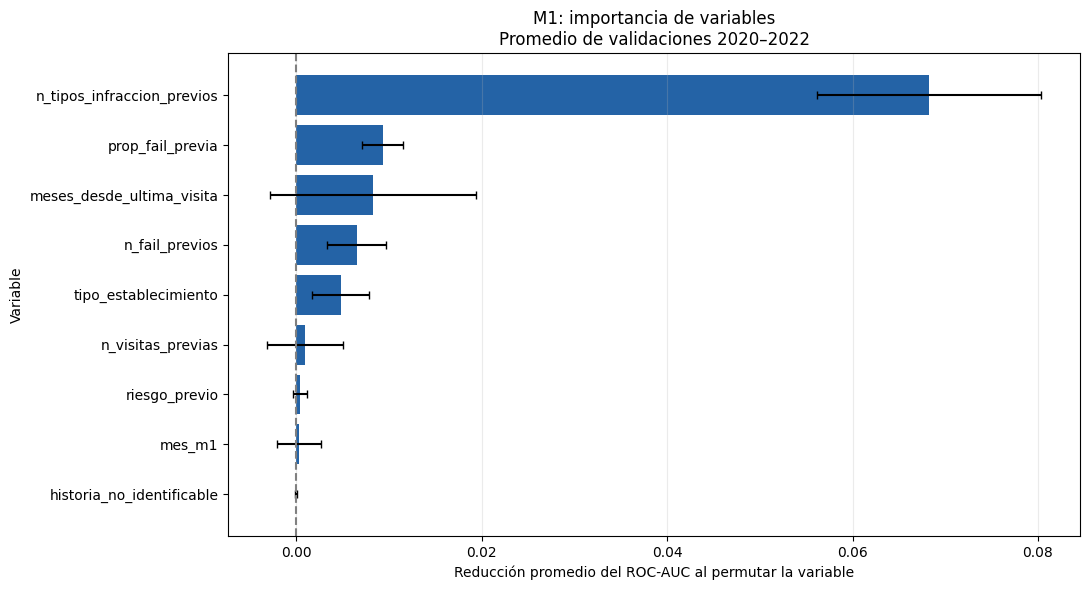

,variable,importancia_media,desviacion
4,n_tipos_infraccion_previos,0.0683,0.0121
6,prop_fail_previa,0.0093,0.0022
2,meses_desde_ultima_visita,0.0083,0.0112
3,n_fail_previos,0.0065,0.0032
8,tipo_establecimiento,0.0048,0.0031
5,n_visitas_previas,0.0009,0.0041
7,riesgo_previo,0.0004,0.0007
1,mes_m1,0.0003,0.0024
0,historia_no_identificable,-0.0000,0.0001


In [ ]:

from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# IMPORTANCIA DE VARIABLES PARA M1 #

# CALCULAR IMPORTANCIA EN CADA VENTANA TEMPORAL #
importancias_m1 = []

for ultimo_anio, anio_validar in ventanas_m1:

    train = m1_desarrollo[
        m1_desarrollo["anio_m1"] <= ultimo_anio
    ]

    val = m1_desarrollo[
        m1_desarrollo["anio_m1"] == anio_validar
    ]

    X_train = train[predictores_m1]
    y_train = train["resultado"].astype(int)

    X_val = val[predictores_m1]
    y_val = val["resultado"].astype(int)

    modelo = construir_m1(
        mejor_cfg[1],
        mejor_cfg[2]
    )

    modelo.fit(X_train, y_train)

    importancia = permutation_importance(
        modelo,
        X_val,
        y_val,
        scoring=auc_fail,
        n_repeats=5,
        random_state=42,
        n_jobs=1
    )

    for i, variable in enumerate(predictores_m1):
        for valor in importancia.importances[i]:

            importancias_m1.append({
                "anio": anio_validar,
                "variable": variable,
                "reduccion_auc": valor
            })


# RESUMIR LAS TRES VENTANAS #

importancias_m1 = pd.DataFrame(importancias_m1)

resumen_importancias = (
    importancias_m1
    .groupby("variable", as_index=False)
    .agg(
        importancia_media=("reduccion_auc", "mean"),
        desviacion=("reduccion_auc", "std")
    )
    .sort_values("importancia_media", ascending=True)
)


# GRÁFICO DE IMPORTANCIA #

plt.figure(figsize=(11, 6))

plt.barh(
    resumen_importancias["variable"],
    resumen_importancias["importancia_media"],
    xerr=resumen_importancias["desviacion"],
    color="#2463A6",
    capsize=3
)

plt.axvline(0, color="gray", linestyle="--")

plt.xlabel("Reducción promedio del ROC-AUC al permutar la variable")
plt.ylabel("Variable")

plt.title(
    "M1: importancia de variables\n"
    "Promedio de validaciones 2020–2022"
)

plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()


# TABLA ORDENADA DE MAYOR A MENOR IMPORTANCIA #

display(
    resumen_importancias
    .sort_values("importancia_media", ascending=False)
    .round(4)
)


# 7. M2 — Árbol podado y SVM

**Fail = 0; Pass o Pass w/ Conditions = 1.** Primero comparamos seis árboles y
cuatro SVM en desarrollo. La reserva 2023–2024 se mantiene para la evaluación final.

## 7.1. Datos y tres particiones temporales

Entrenamos con 2019 y validamos en 2020; entrenamos con 2019–2020 y validamos
en 2021; entrenamos con 2019–2021 y validamos en 2022.
Cada ajuste utiliza todas las filas de entrenamiento de su ventana.

In [ ]:
numericas_m2 = [
    "n_visitas_previas", "n_fail_previos", "prop_fail_previa",
    "n_tipos_infraccion_previos", "meses_desde_ultima_visita",
]
categoricas_m2 = [
    "tipo_establecimiento", "riesgo_previo", "historia_no_identificable",
]

base_m2 = desarrollo.sort_values("inspection_date", kind="stable").copy()
assert base_m2["inspection_date"].between("2019-01-01", "2022-12-31").all()
assert base_m2["resultado"].notna().all()
assert set(base_m2["resultado"].unique()) == {0, 1}
assert not base_m2["inspection_id"].duplicated().any()

X_m2 = base_m2[numericas_m2 + categoricas_m2].copy()
y_m2 = base_m2["resultado"].astype(int)

# Convertir los tipos para que scikit-learn reconozca los faltantes.
for variable in numericas_m2:
    X_m2[variable] = X_m2[variable].to_numpy(dtype=float, na_value=np.nan)
for variable in categoricas_m2:
    valores = X_m2[variable].astype("string")
    X_m2[variable] = valores.astype(object).where(valores.notna(), np.nan)

particiones_m2 = []
tabla_particiones_m2 = []
for anio in [2020, 2021, 2022]:
    fechas = base_m2["inspection_date"]
    entrenamiento = np.flatnonzero(fechas.lt(f"{anio}-01-01").to_numpy())
    validacion = np.flatnonzero(fechas.dt.year.eq(anio).to_numpy())
    assert len(entrenamiento) > 0 and len(validacion) > 0
    assert fechas.iloc[entrenamiento].max() < fechas.iloc[validacion].min()
    particiones_m2.append((anio, entrenamiento, validacion))
    tabla_particiones_m2.append({
        "entrenamiento": f"2019–{anio - 1}", "validacion": anio,
        "n_entrenamiento": len(entrenamiento), "n_validacion": len(validacion),
    })

display(pd.DataFrame(tabla_particiones_m2))

,entrenamiento,validacion,n_entrenamiento,n_validacion
0,2019–2019,2020,8343,6162
1,2019–2020,2021,14505,6230
2,2019–2021,2022,20735,6634


## 7.2. Preparación y diez configuraciones

Los faltantes numéricos se imputan con la mediana y se añaden indicadores de
ausencia. Las categorías se codifican con columnas indicadoras. El SVM también
escala las variables numéricas. Estos pasos se aprenden solo con el entrenamiento
de cada ventana.

In [ ]:
preparacion_categoricas_m2 = Pipeline([
    ("imputar", SimpleImputer(strategy="constant", fill_value="Sin dato")),
    ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preparacion_arbol_m2 = ColumnTransformer([
    ("numericas", SimpleImputer(
        strategy="median", add_indicator=True, keep_empty_features=True,
    ), numericas_m2),
    ("categoricas", clone(preparacion_categoricas_m2), categoricas_m2),
])

preparacion_svm_m2 = ColumnTransformer([
    ("numericas", Pipeline([
        ("imputar", SimpleImputer(
            strategy="median", add_indicator=True, keep_empty_features=True,
        )),
        ("escalar", StandardScaler()),
    ]), numericas_m2),
    ("categoricas", clone(preparacion_categoricas_m2), categoricas_m2),
])

parametros_m2 = {
    "arbol_podado_1": {"ccp_alpha": 0.0001, "min_samples_leaf": 50},
    "arbol_podado_2": {"ccp_alpha": 0.0001, "min_samples_leaf": 150},
    "arbol_podado_3": {"ccp_alpha": 0.001, "min_samples_leaf": 50},
    "arbol_podado_4": {"ccp_alpha": 0.001, "min_samples_leaf": 150},
    "arbol_podado_5": {"ccp_alpha": 0.005, "min_samples_leaf": 50},
    "arbol_podado_6": {"ccp_alpha": 0.005, "min_samples_leaf": 150},
    "svm_1": {"C": 0.5, "gamma": "scale"},
    "svm_2": {"C": 0.5, "gamma": 0.1},
    "svm_3": {"C": 2.0, "gamma": "scale"},
    "svm_4": {"C": 2.0, "gamma": 0.1},
}

## 7.3. Tabla de las diez configuraciones

Cada configuración se ajusta tres veces, una por ventana. Reunimos sus
predicciones de validación de 2020, 2021 y 2022 y calculamos las métricas sobre
esas mismas inspecciones. Así, el AUC corresponde al conjunto de predicciones
de validación reunidas.

El umbral para las métricas de clasificación queda visible en `umbral_fail`.
Con 0.5, se predice Fail cuando su probabilidad es al menos 50 %.

In [ ]:
umbral_fail = 0.25
if not 0 <= umbral_fail <= 1:
    raise ValueError("El umbral debe estar entre 0 y 1")

predicciones_m2 = {}
filas_metricas_m2 = []

for nombre, parametros in parametros_m2.items():
    inicio = perf_counter()
    predicciones_ventanas = []

    for anio, entrenamiento, validacion in particiones_m2:
        modelo = crear_modelo_m2(nombre)
        modelo.fit(X_m2.iloc[entrenamiento], y_m2.iloc[entrenamiento])

        # Buscar explícitamente la columna de la clase 0 = Fail.
        columna_fail = np.flatnonzero(modelo.classes_ == 0).item()
        p_fail = modelo.predict_proba(X_m2.iloc[validacion])[:, columna_fail]

        predicciones_ventanas.append(pd.DataFrame({
            "inspection_id": base_m2.iloc[validacion]["inspection_id"].to_numpy(),
            "id_local": base_m2.iloc[validacion]["id_local"].to_numpy(),
            "inspection_date": base_m2.iloc[validacion]["inspection_date"].to_numpy(),
            "anio": anio,
            "resultado": y_m2.iloc[validacion].to_numpy(),
            "p_fail": p_fail,
        }))
        print(f"Terminado {nombre}: validación {anio}", flush=True)

    predicciones = pd.concat(predicciones_ventanas, ignore_index=True)
    predicciones_m2[nombre] = predicciones
    respuesta = predicciones["resultado"].to_numpy()
    p_fail = predicciones["p_fail"].to_numpy()
    etiquetas = np.where(p_fail >= umbral_fail, 0, 1)

    filas_metricas_m2.append({
        "modelo": nombre,
        "parametros": str(parametros),
        "n_validacion": len(respuesta),
        "prevalencia_fail": (respuesta == 0).mean(),
        "umbral_fail": umbral_fail,
        "auc_roc": roc_auc_score(respuesta == 0, p_fail),
        "log_loss": log_loss(
            respuesta, np.column_stack([p_fail, 1 - p_fail]), labels=[0, 1],
        ),
        "brier": brier_score_loss(respuesta == 0, p_fail),
        "sensibilidad_fail": recall_score(respuesta, etiquetas, pos_label=0, zero_division=0),
        "especificidad": recall_score(respuesta, etiquetas, pos_label=1, zero_division=0),
        "vpp_fail": precision_score(respuesta, etiquetas, pos_label=0, zero_division=0),
        "f1_fail": f1_score(respuesta, etiquetas, pos_label=0, zero_division=0),
        "exactitud": accuracy_score(respuesta, etiquetas),
        "segundos": perf_counter() - inicio,
    })

tabla_modelos_m2 = pd.DataFrame(filas_metricas_m2)
with pd.option_context("display.max_columns", None):
    display(tabla_modelos_m2.round(4))

Terminado arbol_podado_1: validación 2020
Terminado arbol_podado_1: validación 2021
Terminado arbol_podado_1: validación 2022
Terminado arbol_podado_2: validación 2020
Terminado arbol_podado_2: validación 2021
Terminado arbol_podado_2: validación 2022
Terminado arbol_podado_3: validación 2020
Terminado arbol_podado_3: validación 2021
Terminado arbol_podado_3: validación 2022
Terminado arbol_podado_4: validación 2020
Terminado arbol_podado_4: validación 2021
Terminado arbol_podado_4: validación 2022
Terminado arbol_podado_5: validación 2020
Terminado arbol_podado_5: validación 2021
Terminado arbol_podado_5: validación 2022
Terminado arbol_podado_6: validación 2020
Terminado arbol_podado_6: validación 2021
Terminado arbol_podado_6: validación 2022
Terminado svm_1: validación 2020
Terminado svm_1: validación 2021
Terminado svm_1: validación 2022
Terminado svm_2: validación 2020
Terminado svm_2: validación 2021
Terminado svm_2: validación 2022
Terminado svm_3: validación 2020
Terminado svm

,modelo,parametros,n_validacion,prevalencia_fail,umbral_fail,auc_roc,log_loss,brier,sensibilidad_fail,especificidad,vpp_fail,f1_fail,exactitud,segundos
0,arbol_podado_1,"{'ccp_alpha': 0.0001, 'min_samples_leaf': 50}",19026,0.2571,0.25,0.5755,0.5874,0.1942,0.4184,0.7012,0.3265,0.3668,0.6285,0.4554
1,arbol_podado_2,"{'ccp_alpha': 0.0001, 'min_samples_leaf': 150}",19026,0.2571,0.25,0.5801,0.5645,0.1885,0.3144,0.8019,0.3545,0.3333,0.6765,0.4352
2,arbol_podado_3,"{'ccp_alpha': 0.001, 'min_samples_leaf': 50}",19026,0.2571,0.25,0.5486,0.5659,0.1893,0.2061,0.8751,0.3635,0.2630,0.7031,0.4455
3,arbol_podado_4,"{'ccp_alpha': 0.001, 'min_samples_leaf': 150}",19026,0.2571,0.25,0.5486,0.5659,0.1893,0.2061,0.8751,0.3635,0.2630,0.7031,0.4548
4,arbol_podado_5,"{'ccp_alpha': 0.005, 'min_samples_leaf': 50}",19026,0.2571,0.25,0.5128,0.5716,0.1916,0.0000,1.0000,0.0000,0.0000,0.7429,0.4469
5,arbol_podado_6,"{'ccp_alpha': 0.005, 'min_samples_leaf': 150}",19026,0.2571,0.25,0.5128,0.5716,0.1916,0.0000,1.0000,0.0000,0.0000,0.7429,0.4248
6,svm_1,"{'C': 0.5, 'gamma': 'scale'}",19026,0.2571,0.25,0.5438,0.5685,0.1904,0.2686,0.7921,0.3090,0.2874,0.6575,460.8791
7,svm_2,"{'C': 0.5, 'gamma': 0.1}",19026,0.2571,0.25,0.5438,0.5685,0.1904,0.2835,0.7790,0.3075,0.2950,0.6516,442.8674
8,svm_3,"{'C': 2.0, 'gamma': 'scale'}",19026,0.2571,0.25,0.5410,0.5689,0.1905,0.2817,0.7798,0.3069,0.2938,0.6517,522.0077
9,svm_4,"{'C': 2.0, 'gamma': 0.1}",19026,0.2571,0.25,0.5413,0.5697,0.1909,0.2982,0.7616,0.3022,0.3002,0.6425,536.3369


Elegimos los modelos respecto al `AUC_ROC`, por tanto, elegimos el Árbol 2 y el SVM 1.

In [ ]:
modelo_arbol = "arbol_podado_2"
modelo_svm = "svm_1"

## 7.4. ROC y matrices de confusión de los dos elegidos

Esta celda requiere completar la selección anterior. Los gráficos usan las
predicciones de validación ya guardadas; no vuelven a ajustar los modelos.
Son diagnósticos de desarrollo para apoyar tu elección final.

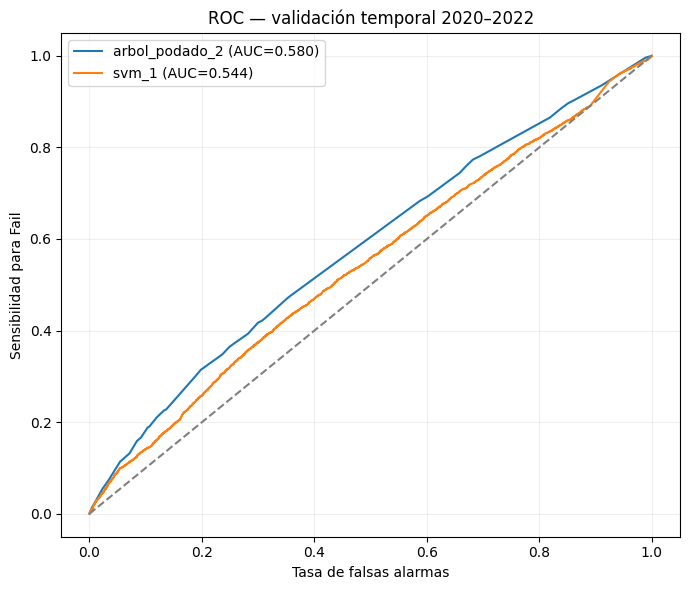

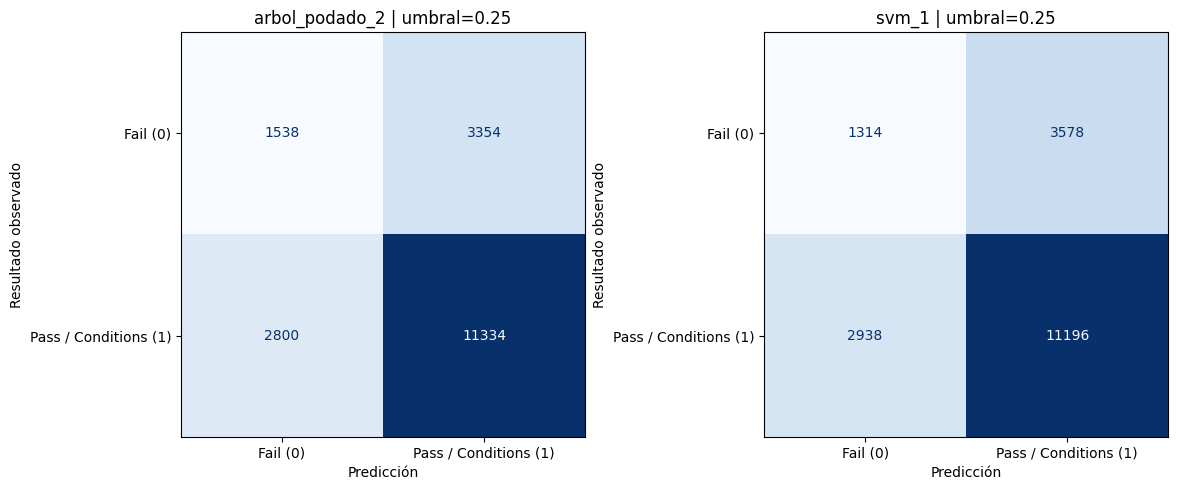

In [ ]:
if modelo_arbol not in parametros_m2 or not str(modelo_arbol).startswith("arbol_podado_"):
    raise ValueError("Completa modelo_arbol con un nombre válido, por ejemplo 'arbol_podado_2'")
if modelo_svm not in parametros_m2 or not str(modelo_svm).startswith("svm_"):
    raise ValueError("Completa modelo_svm con un nombre válido, por ejemplo 'svm_3'")
if not 0 <= umbral_fail <= 1:
    raise ValueError("El umbral debe estar entre 0 y 1")

elegidos_m2 = [modelo_arbol, modelo_svm]

fig, ax = plt.subplots(figsize=(7, 6))
for nombre in elegidos_m2:
    predicciones = predicciones_m2[nombre]
    evento_fail = predicciones["resultado"].eq(0)
    p_fail = predicciones["p_fail"]
    fpr, tpr, _ = roc_curve(evento_fail, p_fail)
    auc = roc_auc_score(evento_fail, p_fail)
    ax.plot(fpr, tpr, label=f"{nombre} (AUC={auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray")
ax.set_xlabel("Tasa de falsas alarmas")
ax.set_ylabel("Sensibilidad para Fail")
ax.set_title("ROC — validación temporal 2020–2022")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, nombre in zip(axes, elegidos_m2):
    predicciones = predicciones_m2[nombre]
    etiquetas = np.where(predicciones["p_fail"] >= umbral_fail, 0, 1)
    matriz = confusion_matrix(predicciones["resultado"], etiquetas, labels=[0, 1])
    ConfusionMatrixDisplay(
        matriz, display_labels=["Fail (0)", "Pass / Conditions (1)"],
    ).plot(ax=ax, colorbar=False, cmap="Blues", values_format="d")
    ax.set_title(f"{nombre} | umbral={umbral_fail:.2f}")
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Resultado observado")
plt.tight_layout()
plt.show()

## 7.5. Elección de M2 y ajuste con 2019–2022

In [ ]:
modelo_m2 = "arbol_podado_2"

In [ ]:
if modelo_m2 not in parametros_m2 or modelo_m2 not in [modelo_arbol, modelo_svm]:
    raise ValueError("Completa modelo_m2 con uno de los dos nombres elegidos anteriormente")

modelo_m2_entrenado = crear_modelo_m2(modelo_m2)
modelo_m2_entrenado.fit(X_m2, y_m2)

print("Modelo ajustado:", modelo_m2)
print("Parámetros:", parametros_m2[modelo_m2])
print("Inspecciones de entrenamiento:", len(y_m2))
print("Periodo: 2019–2022")

Modelo ajustado: arbol_podado_2
Parámetros: {'ccp_alpha': 0.0001, 'min_samples_leaf': 150}
Inspecciones de entrenamiento: 27369
Periodo: 2019–2022
